## Abstract

Transformers trained on planetary orbits can predict planet movement with high fidelity under multiple possible 'World models'. Understanding which world model a transformer has learned to represent is an open problem. Here we apply Equivalent Linear Mapping to precisely characterize how a short-context transformer builds its predictions from two past orbital positions. 

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

Liu et al. (2026) showed that transformers trained to predict planetary motion learn qualitatively different world models depending on context length using linear probes which reveal what could be encoded, but not how the network computes with it. Here we open the box: we apply **Equivalent Linear Mapping (ELM)** to rewrite the trained transformer as an exact per-token linear map and read the gravitational force directly out of its Jacobian. 


## Introduction

The strong performance of foundation models across scientific domains has spurred interest in their internal workings, and in particular in the "world models" they are said to learn. Loosely, a world model is the internal representation a network builds of the process that generated its training data which shapes the implicit rules it learns to use to make predictions. A line of work beginning with sequence models trained on board games [Li et al., 2022] has shown that such representations can emerge spontaneously: a network trained only to predict the next token can be found to encode structured features of the underlying system it was never told about.

Several approaches have been used to identify these learned world models, each with a characteristic blind spot. Linear probes test whether a variable of interest can be decoded from a learned representation, and decodability is often taken as evidence that the model represents and reasons with that variable. But this inference is fragile. The success of a probe is contingent on the chosen target and how it is parameterized — what is not linearly decodable under one encoding can become so under another [Nanda et al., 2023] — and, more fundamentally, a probe reports what is *encoded*, not what is *computed with* [Ravichander et al., 2020]. Behavioral tests trade encoding for function: by probing the input–output map out of distribution, they can establish whether a network's behavior is consistent with a hypothesized world model and rule mechanisms out [Vafa et al., 2025]. But behavior alone cannot positively identify the internal computation, since two networks running different mechanisms are indistinguishable wherever those mechanisms happen to agree. Mechanistic analysis targets what neither of the others can reach — the computation itself — by describing how a network actually transforms its inputs into predictions, and it is the approach we take here.

We study a setting where these distinctions become concrete and where the mechanism can be read out exactly. We build on [Liu et al., 2026], who trained small transformers to predict planetary motion from past positions and used linear probes to argue that their models learn different world models depending on context length: short-context models appeared to encode Newtonian force variables, long-context models Keplerian orbital geometry — a phase transition they attribute to the inductive bias of context length. Rather than probing what is encoded, we apply equivalent linear mapping (ELM) to rewrite the trained network as an exact per-token linear map and read its mechanism directly off the resulting Jacobian. Taking the Verlet integrator as a reference computation compatible with a Newtonian world model, we ask how closely each network's recovered map matches it. We find that the short-context transformer of Liu et al. computes a circular-rotation heuristic — despite carrying linearly decodable Newtonian force variables — a mechanism that coincides with Newtonian dynamics on the near-circular orbits that dominate training but diverges from it beyond them. We trace this to the input noise the authors inject during training to stabilize rollouts. Retraining the short-context model without noise yields a network whose token-level operations closely match Verlet integration, consistent with a genuine Newtonian world model. Our analysis is thus a worked example of identifying a network's internal computation without internal probing, and of adjudicating between candidate world models against a known ground truth when one is available.


## The Setup

The training data is 2D planetary orbits under an inverse-square force, $\ddot{\mathbf r} = -\,GM\,\mathbf r/|\mathbf r|^{3}$ (units with $GM=1$). The transformer reads a sequence of past positions $\mathbf r_0, \mathbf r_1, \dots$ and predicts the next one, $\hat{\mathbf r}_{t+1}$. Its context length (block size) is how many past positions it may attend to. Two alternative models can in principle be used to fit the training data with high fidelity:

- a **Newtonian** model — estimate the local gravitational force from the last one or two positions and integrate $F = ma$
- a **Keplerian** model — fit the global ellipse through the observed points and continue along it

**The data.** We reuse Liu et al.'s data-generation procedure. Each trajectory is a bound elliptical orbit obtained by numerically integrating $\ddot{\mathbf r} = -GM\,\mathbf r/|\mathbf r|^3$ ($GM = 1$) with `scipy`'s `solve_ivp` at relative and absolute tolerances of $10^{-8}$. Orbits are initialized at perihelion with parameters drawn uniformly — eccentricity $e \in [0, 0.8]$, semi-major axis $a \in [0.5, 2.0]$, and orientation $\theta \in [0, 2\pi]$ — with the initial state rotated by $\theta$. Each trajectory is sampled at 100 equally spaced points, giving sequences of shape $(100, 2)$. The nominal step is $\Delta t = 0.2$, but the generator lays the 100 samples out over $[0, 20]$ with `linspace`, so the true spacing is $20/99 \approx 0.202$ — 1% wider. We inherit this from Liu et al.'s generator and use the true spacing wherever we compare the model against a physical formula. Note the eccentricity distribution is broad (uniform up to $e = 0.8$, mean $0.4$): the typical training orbit is appreciably non-circular, which will matter when we characterize what the short-context model actually learns.

**What we train.** We re-train Liu et al.'s model — a small GPT-2-style transformer (a modified nanoGPT) — from scratch at the two context lengths that bracket their result, 2 and 100. We train two variants at each context length: a noisy model, using Liu et al.'s noisy-context training (input positions perturbed by Gaussian noise, $\sigma = 0.1$) that stabilises autoregressive prediction, and a noiseless model ($\sigma = 0$). Our one departure from their setup is that we disable every bias term as the ELM analysis below needs the network to be a homogeneous linear map at each operating point.

With the models in hand, our first two analyses set up the tools the rest of the pub relies on: (1) the ELM decomposition is exact, so its per-token attributions are trustworthy; and (2) linear probing reproduces the phase transition reported by Liu et al. on these checkpoints.

::: {.callout-note collapse="true" title="Model architecture and training (details)"}

**Architecture.** Each model is a small decoder-only GPT (a bias-free modification of nanoGPT), identical at the two context lengths except for the block size:

- **Depth/width:** 2 pre-norm transformer blocks, 1 attention head, embedding dimension $d_{\text{model}} = 32$ (MLP hidden width $4d = 128$, SiLU activation), for $\approx\!25\text{k}$ parameters total.
- **Continuous I/O (no tokenizer):** each 2D position $\mathbf r_t \in \mathbb{R}^2$ is linearly projected into the 32-dim residual stream, a learned positional embedding $\mathrm{wpe}[t]$ is added, and a final linear head maps the stream back to $\mathbb{R}^2$ to predict the next position.
- **Context length (block size):** 2 or 100.
- **No bias terms:** attention heads, MLP, LayerNorm, and both I/O projections (see ELM section for explanation) are trained with no biases. Standard LayerNorm (scale only), dropout $0$, and no log-position attention scaling ($\alpha = 0$).

**Training.**

- **Data:** 10,000 trajectories for training and 10,000 held out for test, each 100 points long, chopped into sliding (input-window, next-position) pairs.
- **Objective:**  mean-squared error on the next-position prediction, one step ahead, with no autoregressive rollout in the loss. At context length 100 every input position is supervised, each against the position that follows it; at context length 2 each training window carries a single target, so only the prediction made from the full window  ($\hat{\mathbf r}{t+1}$) from $(\mathbf r{t-1}, \mathbf r_t)$ is supervised.
- **Optimizer:** AdamW, learning rate $10^{-3}$ decayed by $10\times$ at the halfway point, weight decay $0$, batch size $128$, $20{,}000$ steps, seed $1$.
- **Noisy-context augmentation:** input positions are perturbed with Gaussian noise $\mathcal{N}(0, \sigma^2)$ during training. We train a noisy short-context model ($\sigma = 0.1$, following Liu et al.) and a noiseless one ($\sigma = 0$) at block size 2, plus a noisy long-context model ($\sigma = 0.1$, block size 100).

The architecture, weight initialization, and data-generation procedure follow Liu et al. (arXiv:2602.06923); disabling the bias terms is our only architectural change. Full definitions are in `src/analysis/model.py` and `src/analysis/training.py`.

:::

In [1]:
#| code-fold: true
#| output: false
import io
import os
import contextlib

import numpy as np
import torch
import matplotlib.pyplot as plt

from analysis.model import load_from_checkpoint

torch.set_default_dtype(torch.float64)   # ELM reconstruction is exact only at float64

CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'
DATA_DIR       = 'data_cv'
NUM_TRAJ, NOISE_SCALE, SEED = 10000, 0.1, 0

# Sample spacing of the trajectories. NOT the nominal 0.2: the upstream generator
# samples with t_eval = linspace(0, num_points*dt, num_points), so 100 points over
# [0, 20] land 20/99 apart. Used wherever we compare the model to a physical formula.
DT = 20 / 99
CKPT_BS2   = f'{CHECKPOINT_DIR}/model_block_size_2_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
CKPT_BS100 = f'{CHECKPOINT_DIR}/model_block_size_100_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'

with contextlib.redirect_stdout(io.StringIO()):
    model_bs2,   _ = load_from_checkpoint(CKPT_BS2,   device='cpu'); model_bs2.eval()
    model_bs100, _ = load_from_checkpoint(CKPT_BS100, device='cpu'); model_bs100.eval()


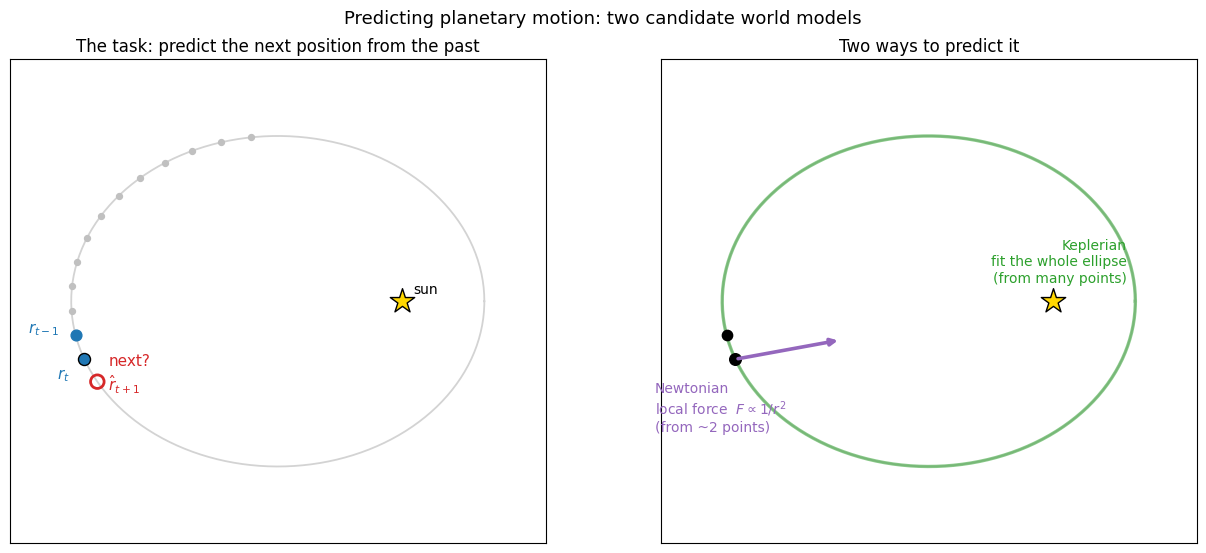

In [2]:
#| label: fig-setup
#| fig-cap: "The prediction task and the two candidate world models. Left: the transformer sees past positions along an orbit (blue = the two most recent) and must predict the next one. Right: a Newtonian rule estimates the local inverse-square force from the last couple of positions and integrates it; a Keplerian rule fits the global ellipse through many points and continues along the curve."
#| code-fold: true
_a, _e = 1.35, 0.6; _b = _a*np.sqrt(1-_e**2); _c = _a*_e
_E = np.linspace(0, 2*np.pi, 300); _ex, _ey = _a*np.cos(_E), _b*np.sin(_E); _sun = np.array([_c, 0.0])
_Es  = np.linspace(1.7, 3.5, 13)
_pts = np.stack([_a*np.cos(_Es), _b*np.sin(_Es)], 1)
_rp, _rt = _pts[-2], _pts[-1]
_En = 2*_Es[-1] - _Es[-2]; _rn = np.array([_a*np.cos(_En), _b*np.sin(_En)])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.6))
for ax in (axA, axB):
    ax.plot(_ex, _ey, color='lightgray', lw=1.3, zorder=0)
    ax.scatter(*_sun, marker='*', s=340, color='gold', edgecolor='k', zorder=6)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(-_a-0.4, _a+0.4); ax.set_ylim(-_b-0.5, _b+0.5)
axA.scatter(_pts[:-2, 0], _pts[:-2, 1], s=18, color='silver', zorder=3)
axA.scatter(*_rp, s=60, color='tab:blue', zorder=4); axA.scatter(*_rt, s=75, color='tab:blue', edgecolor='k', zorder=4)
axA.scatter(*_rn, s=95, facecolor='none', edgecolor='tab:red', lw=2, zorder=5)
axA.annotate(r'$r_{t-1}$', _rp, textcoords='offset points', xytext=(-34, 2), color='tab:blue', fontsize=11)
axA.annotate(r'$r_t$', _rt, textcoords='offset points', xytext=(-20, -14), color='tab:blue', fontsize=11)
axA.annotate('next?\n$\hat r_{t+1}$', _rn, textcoords='offset points', xytext=(8, -6), color='tab:red', fontsize=11)
axA.annotate('sun', _sun, textcoords='offset points', xytext=(8, 6), fontsize=10)
axA.set_title('The task: predict the next position from the past', fontsize=12)
axB.scatter(*_rp, s=55, color='k', zorder=4); axB.scatter(*_rt, s=70, color='k', edgecolor='k', zorder=4)
_d = _sun - _rt; _d = _d/np.linalg.norm(_d)*0.7
axB.annotate('', xy=_rt + _d, xytext=_rt, arrowprops=dict(arrowstyle='-|>', color='tab:purple', lw=2.6), zorder=5)
axB.annotate('Newtonian\nlocal force  $F\propto 1/r^2$\n(from ~2 points)', _rt, textcoords='offset points', xytext=(-58, -52), color='tab:purple', fontsize=10)
axB.plot(_ex, _ey, color='tab:green', lw=2.4, alpha=0.55, zorder=2)
axB.annotate('Keplerian\nfit the whole ellipse\n(from many points)', (_ex.max(), 0), textcoords='offset points', xytext=(-6, 14), color='tab:green', fontsize=10, ha='right')
axB.set_title('Two ways to predict it', fontsize=12)
fig.suptitle('Predicting planetary motion: two candidate world models', fontsize=13)
fig.tight_layout(); plt.show()


## Applying the ELM decomposition

A transformer is nonlinear, so in general no single matrix maps its input to its output. But the nonlinearity is concentrated in a few input-dependent transformations such how strongly each vector is normalised, which neurons the gates switch on, and where attention looks. **Equivalent Linear Mapping (ELM)** freezes those choices at the values they take for one specific input $x^*$ and detaches them from the gradient (Golden 2026). For that input the network then behaves as an exact linear map, which we can read off as a set of per-token detached Jacobian matrices $J_t(x^*)$ and interpret directly:

$$y^* \;=\; \sum_t J_t(x^*)\, x_t^* \qquad\text{(exact at }x^*\text{).}$$

This exact form is homogeneous (it carries no additive constant) which is why we trained the models with all bias terms disabled (see the Setup): a bias would inject a constant offset that no per-token detached Jacobian could absorb, breaking the reconstruction.

Three nonlinearities are frozen: the LayerNorm scale, the SiLU gate, and the attention weights, after which the input-to-output map is exactly linear-homogeneous at $x^*$. The details of how each is detached are below.

::: {.callout-note collapse="true" title="How the three nonlinearities are detached"}
- **LayerNorm denominator** — the RMS normalisation constant $\sigma(x^*)$ is frozen, so the gradient sees only the linear numerator $x / \sigma(x^*)$. The mean-centering $(x - \bar{x})$ is *kept* in the gradient path because it is itself linear (multiplication by $C = I - \mathbf{1}\mathbf{1}^\top/d$).
- **SiLU gate** — $\text{SiLU}(x) = x\cdot\sigma(x)$ is linearised as $x\cdot\sigma(x^*)$, freezing the sigmoid factor so only the linear $x$ carries gradient.
- **Attention weights** — both the query $Q$ and key $K$ are detached before the score computation, freezing the full attention matrix $A(x^*)$; gradient flows only through the value path $V = W_V x$. Detaching only $\text{softmax}(QK^\top)$ would be insufficient because $Q$ and $K$ themselves depend on $x$.
:::

**Content vs. positional split.** The transformer architecture used by Liu et al. adds a positional embedding to each token, $h_t = W_{\rm in} x_t + \mathrm{wpe}[t]$, the one constant offset we do not remove from the model. To get around this, we differentiate downstream of that embedding sum, treating $h_t$ as the variable, which is exactly linear after detachment and splits cleanly into a part driven by the input positions and a part driven by the (input-independent[^2]) positional embeddings:

$$y^* = \underbrace{\sum_t J_{h,t}\, W_{\rm in}\, x_t}_{\text{content}} +
        \underbrace{\sum_t J_{h,t}\, \mathrm{wpe}[t]}_{\text{positional}}.$$

The content term gives the $2\times 2$ blocks $J_{x,t} = J_{h,t}\,W_{\rm in}$ (in $(x,y)$ space) that we interpret throughout.

**Verification.** @fig-elm-recon plots the model's true forward output against the ELM reconstruction (content + positional) for the last output token, at both context lengths. The points lie on the identity line with relative error $\sim\!10^{-16}$ (machine precision): the Jacobian is an exact stand-in for the model at $x^*$, so the per-token attributions used in the rest of this pub are trustworthy.

[^2]:The positional embeddings are a static lookup table, invariant with respect to inputs in $(x,y)$ space, which is what lets us split them off from the content terms. The positional *contribution* $\sum_t J_{h,t}\,\mathrm{wpe}[t]$ is not input-independent, though, because the detached Jacobians $J_{h,t}$ vary with the operating point. It is small relative to the prediction but not relative to the small non-inertial correction, so we measure it directly rather than setting it aside (@fig-kick-terms).


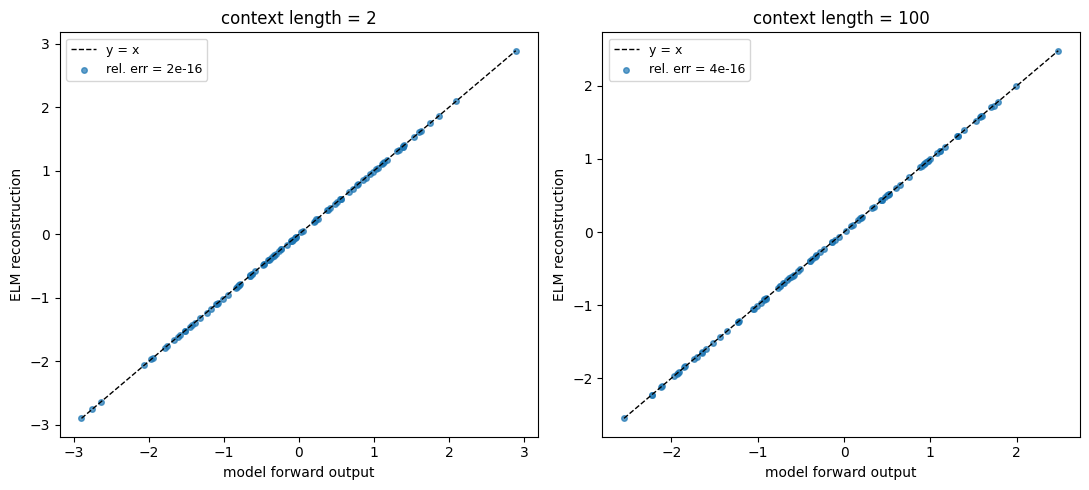

In [3]:
#| label: fig-elm-recon
#| fig-cap: "ELM reconstruction vs. model forward output for the last token, at context length 2 and 100. Points on the identity line (relative error ~1e-16, machine precision) confirm the detached Jacobian is an exact linear decomposition of the model."
#| code-fold: true
from analysis.elm import reconstruction_scatter

mv_2,   ev_2   = reconstruction_scatter(model_bs2,   2,   n_windows=50, seed=SEED)
mv_100, ev_100 = reconstruction_scatter(model_bs100, 100, n_windows=50, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, mv, ev, label in [(axes[0], mv_2,   ev_2,   'context length = 2'),
                          (axes[1], mv_100, ev_100, 'context length = 100')]:
    err = np.linalg.norm(ev - mv) / np.linalg.norm(mv)
    lo, hi = float(min(mv.min(), ev.min())), float(max(mv.max(), ev.max()))
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x')
    ax.scatter(mv, ev, s=16, c='tab:blue', alpha=0.7, label=f'rel. err = {err:.0e}')
    ax.set_xlabel('model forward output'); ax.set_ylabel('ELM reconstruction')
    ax.set_title(label); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()


## Replicating linear probe results

Now that we have an ELM compatible version of the short/long context models, we need to verify that our re-trained transformers recapitulate the probing results reported by Liu et al. We repeat the probing analysis used to generate Figure 6a/b by the authors, probing each layer of the model for physical quantities compatible with either Newtonian or Keplerian models, reporting the best layer's $R^2$. The Newtonian targets are local, the gravitational force $\mathbf F = -\mathbf r/|\mathbf r|^3$ and its components $F_x, F_y$, computable from the current position alone. The Keplerian targets describe the whole orbit: the semi-major and semi-minor axes $a, b$ (its size and shape), and the Laplace–Runge–Lenz vector $\mathbf A = (A_x, A_y)$, which points along the major axis toward perihelion and so encodes the orbit's orientation and eccentricity.

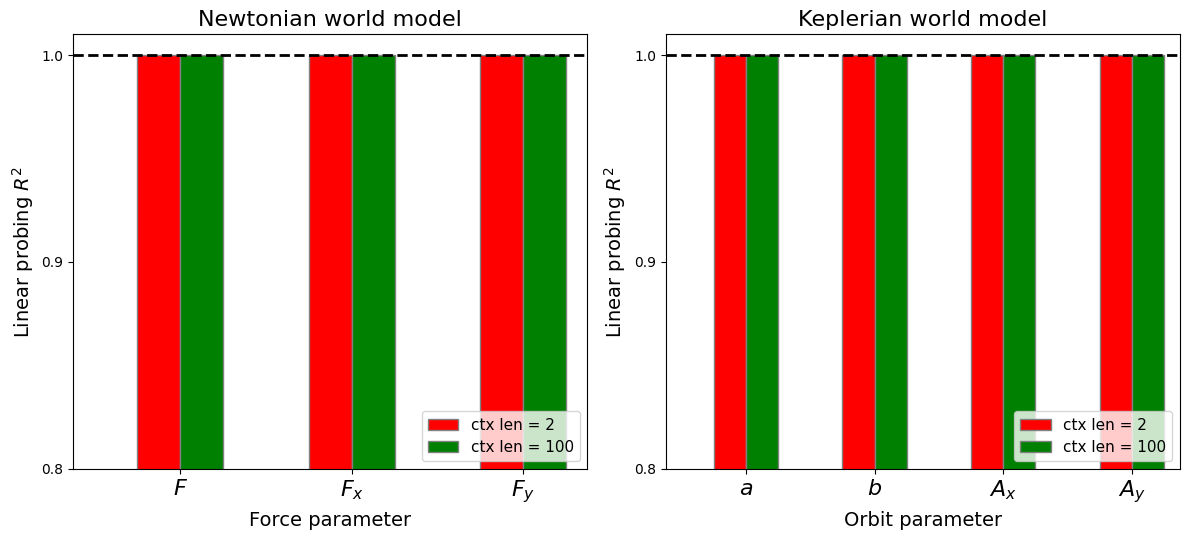

In [4]:
#| label: fig-phase-transition
#| fig-cap: "Best-layer, last-position linear-probing R² for Newtonian force variables (left) and Keplerian orbital parameters (right), at context length 2 vs 100. Short context encodes forces; long context encodes orbital geometry — consistent with Liu et al. within run-to-run variance."
#| code-fold: true
from analysis.data import load_trajectories, load_orbital_params
from analysis.probing import probe_model, best_r2

with contextlib.redirect_stdout(io.StringIO()):
    trajs    = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=NUM_TRAJ))
    o_params = load_orbital_params(DATA_DIR, num_trajectories_needed=NUM_TRAJ)
    newton_2,   kepler_2   = probe_model(model_bs2,   trajs, o_params, 2,   n_probe=100, seed=SEED)
    newton_100, kepler_100 = probe_model(model_bs100, trajs, o_params, 100, n_probe=100, seed=SEED)

NEWTON = [('F_magnitude', r'$F$'), ('Fx', r'$F_x$'), ('Fy', r'$F_y$')]
KEPLER = [('a', r'$a$'), ('b', r'$b$'), ('LRL_x', r'$A_x$'), ('LRL_y', r'$A_y$')]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, xlabel, items, p2, p100) in zip(axes, [
        ('Newtonian world model', 'Force parameter', NEWTON, newton_2, newton_100),
        ('Keplerian world model', 'Orbit parameter', KEPLER, kepler_2, kepler_100)]):
    targets = [t for t, _ in items]; ticklab = [l for _, l in items]
    r2_2   = [best_r2(p2,   t) for t in targets]
    r2_100 = [best_r2(p100, t) for t in targets]
    bw = 0.25; br1 = np.arange(len(targets))
    b1 = ax.bar(br1,      r2_2,   bw, color='r', edgecolor='grey', label='ctx len = 2')
    b2 = ax.bar(br1 + bw, r2_100, bw, color='g', edgecolor='grey', label='ctx len = 100')
    ax.plot([-0.5, len(targets) - 0.5], [1, 1], '--', color='black', lw=2)
    ax.set_xlim(-0.5, len(targets) - 0.5); ax.set_ylim(0.8, 1.01); ax.set_yticks([0.8, 0.9, 1.0])
    ax.set_xticks(br1 + 0.5 * bw); ax.set_xticklabels(ticklab, fontsize=16)
    ax.set_xlabel(xlabel, fontsize=14); ax.set_ylabel(r'Linear probing $R^2$', fontsize=14)
    ax.set_title(title, fontsize=16); ax.legend(handles=[b1, b2], fontsize=11, loc='lower right')
fig.tight_layout(); plt.show()


@fig-phase-transition shows the result of the linear probing. At context length 2, probing recover Newtonian force components almost perfectly and above the orbital-geometry variables; at context length 100 that ranking flips, with the geometry variables best predicted. Notably every target stays decodable at $R^2$>0.9 at both context lengths, the "transition" is a shift in which world model is best encoded, not a presence/absence switch[^1]. This is the same overall result Liu et al. identified, and our checkpoints reproduce it (consistent within run-to-run variance).

Confident that our models are behaving as expected, we now focus on using ELM to understand how input coordinates are combined to generate future positional predictions in the short-context model. We restrict our analyses to this model for two reasons, 1) the limited number of input tokens makes it easier to interpret a smaller number of per-token Jacobians, and 2) the short context model is the one that appears to learn the 'correct' world model according to linear probing and is thus most interesting to unpack. 

[^1]: We also note that the linear probe $R^2$ values are quite sensitive to low sample size, leading to very high values (likely from overfitting).

## Inside the short-context model

The probes tell us we can decode force variables using a linear transformation from the models latent representations, but this does not guarantee the model actually uses these values in a meaningful way. With ELM we can read out the actual computation: how the model turns the two positions it sees, $\mathbf r_{t-1}$ and $\mathbf r_t$, into its prediction $\hat{\mathbf r}_{t+1}$.

Here we must address what it would mean for this computation to reflect a genuinely learned Newtonian world model. Since the training task is to predict a single future position, many heuristics can approximate it well without implementing the underlying physics. Simply copying the last position (persistence, $\hat{\mathbf r}_{t+1} = \mathbf r_t$) already achieves high $R^2$, since consecutive positions are close. More subtly, geometrically aware heuristics like rotations could reproduce the *appearance* of a central force, and even produce hidden states from which force components are linearly decodable, without computing the force law itself. Predictive accuracy, and even a passing linear probe, therefore cannot establish that a model has learned Newtonian gravity. Our criterion is instead structural: does the recovered computation match that of a Newtonian mechanics derived integrator? Since ELM recovers the exact linear combination of the two input positions used to form the prediction, we can compare it directly to a textbook solution of Newtonian orbital mechanics. Our reference is the second-order Verlet integrator:

$$\hat{\mathbf r}_{t+1} = 2\,\mathbf r_t - \mathbf r_{t-1} - \Delta t^2\,\nabla\phi(\mathbf r_t).$$

The inertial part $2\mathbf r_t - \mathbf r_{t-1}$ is constant-velocity coasting, rewritten as $\mathbf r_t + (\mathbf r_t - \mathbf r_{t-1})$, it reads "current position plus the last step's displacement." The final term is the small gravitational kick. A genuine force integrator therefore weights its two inputs by $(c_{\text{prev}}, c_{\text{recent}}) = (-1, 2)$ before the force correction; we call $(-1, 2)$ the **inertial point**.

Because the inertial terms should usually dominate the update, a first-pass test for Verlet structure is whether the model carries these coasting weights at all. We read them off the Jacobian: each per-token block $J_s$ is $2\times2$, and its isotropic part $c_s = \mathrm{tr}(J_s)/D$ (here $D=2$) is the scalar by which input position $s$ is uniformly scaled into the prediction. A genuine force integrator should land near $(c_{\text{prev}}, c_{\text{recent}}) = (-1, 2)$. This isotropic test probes the inertial backbone, whether the small residual correction is the Newtonian force term is a separate question we take up in downstream analyses.

In [5]:
#| code-fold: true
#| output: false
# Mechanistic analysis of the short-context (noise=0.1) model. Reuses the model and
# constants loaded in the intro setup; only adds the analysis helpers.
from analysis import elm as NT
from analysis.data import load_trajectories

model = model_bs2                 # the bs=2, noise=0.1 model from the intro

BLOCK_SIZE    = 2
N_WINDOWS     = 900               # Jacobian-based analyses (expensive; ~14 s per model).
                                  # 900 keeps ~180 windows per radius bin in the binned
                                  # panel below, enough for its bootstrap CIs to separate
                                  # the terms from the ideal kick.
N_WINDOWS_BEH = 4000              # behavioural analyses (cheap forward passes)
SPLIT  = 'test'
OFFSET = 0 if SPLIT == 'train' else NUM_TRAJ   # 50/50 train/test split, by trajectory

def load_split_trajectories(n, data_dir=DATA_DIR, offset=None):
    offset = OFFSET if offset is None else offset
    with contextlib.redirect_stdout(io.StringIO()):
        trajs = np.asarray(load_trajectories(data_dir, num_trajectories_needed=offset + n))
    return trajs[offset:offset + n]


In [6]:
#| code-fold: true
#| output: false
# Per-token Jacobian blocks over N_WINDOWS real-orbit windows (slow; ~1-2 min).
# collect_terms also returns the size of each term in the ELM sum (the two
# content contributions and the positional one), used in the right-hand panel below.
all_blocks, coeffs, content, positional, radius, recon_err_max = NT.collect_terms(
    model, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]
D = all_blocks.shape[-1]


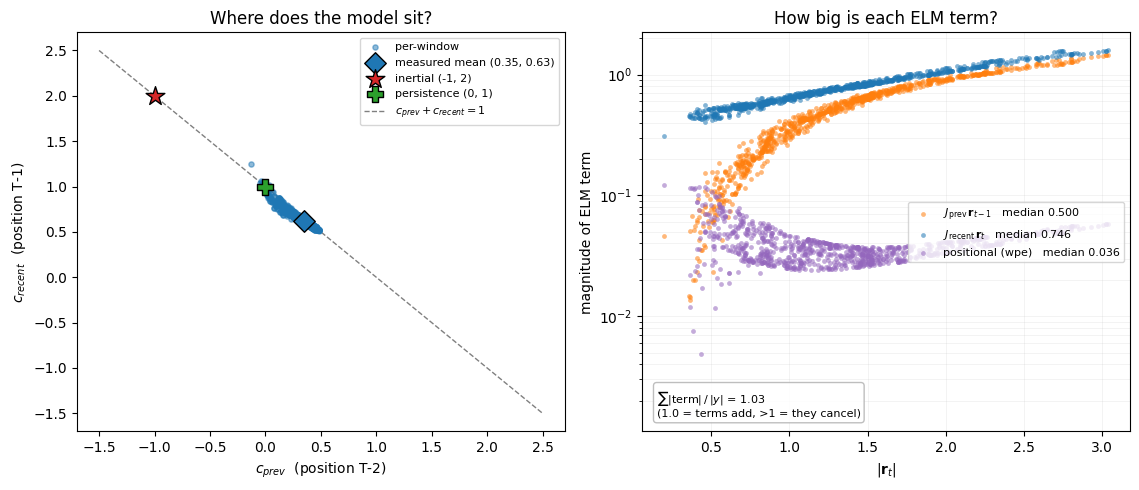

In [7]:
#| label: fig-verlet-coeff
#| fig-cap: "Left: the noisy bs=2 model in (c_prev, c_recent) space, where c_s = tr(J_s)/D is each token's isotropic weight. Per-window points (blue) cluster near (0.35, 0.63) on the persistence line c_prev + c_recent = 1 - a weighted average of the two inputs - far from the inertial point (-1, 2) that a forward-extrapolating integrator would occupy. Right: the size of every term in the ELM sum for the same windows (log scale). The two content terms are comparable and add (sum of magnitudes / |y| = 1.03), as a weighted average should; the positional (wpe) term contributes 2.6% of the prediction, which is why it is left out of the coefficient analysis."
#| code-fold: true
positions = np.arange(T)
c_mean, c_std = coeffs.mean(0), coeffs.std(0)

target = np.zeros(T); target[T-1] = 2.0; target[T-2] = -1.0

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
ax = axes[0]

c_prev, c_recent = coeffs[:, T-2], coeffs[:, T-1]
ax.scatter(c_prev, c_recent, s=14, alpha=0.5, color='tab:blue', label='per-window', zorder=2)
ax.scatter([c_prev.mean()], [c_recent.mean()], s=120, marker='D', color='tab:blue', edgecolor='k',
           label=f'measured mean ({c_prev.mean():.2f}, {c_recent.mean():.2f})', zorder=4)
ax.scatter([-1], [2], s=200, marker='*', color='tab:red', edgecolor='k', label='inertial (-1, 2)', zorder=5)
ax.scatter([0], [1], s=120, marker='P', color='tab:green', edgecolor='k', label='persistence (0, 1)', zorder=4)
lo = min(-1.5, float(c_prev.min())); hi = max(2.5, float(c_recent.max()))
xs = np.linspace(lo, hi, 50)
ax.plot(xs, 1 - xs, ls='--', color='gray', lw=1, label=r'$c_{prev}+c_{recent}=1$', zorder=1)
ax.set_xlabel(r'$c_{prev}$  (position T-2)')
ax.set_ylabel(r'$c_{recent}$  (position T-1)')
ax.set_title('Where does the model sit?')
ax.legend(fontsize=8, loc='best')

# Right panel: how big is each term in the ELM sum?  The coefficient analysis on
# the left uses the content Jacobians only, so show what the omitted positional
# term is worth alongside them.
NT.plot_term_magnitudes(axes[1], content, positional, radius)
axes[1].set_title('How big is each ELM term?')

fig.tight_layout()
plt.show()


@fig-verlet-coeff shows the input token Jacobians do not sit near the inertial point rather their isotropic coefficients are $(c_{\text{prev}}, c_{\text{recent}}) \approx (0.35, 0.63)$. The noisy model's two positive weights make its prediction a weighted average of its inputs. So it is not doing textbook Newtonian integration.

A guess at what it is doing can be gleaned by inspecting the average of the entire Jacobian block (of both tokens) for a small sample of predictions. @fig-jacobian-rotation shows the averaged per-token blocks: both look like scaled rotation matrices containing equal diagonals and equal-and-opposite off-diagonals[^3], i.e. $J_s \approx c_s\,R(\theta_s)$. The model does not push $\mathbf r_t$ forward rather it likely turns it. 


[^3]:Note that this rotational structure emerges so cleanly because all simulated orbits have an anti-clockwise direction, so the off diagonal sign changes do not cancel out

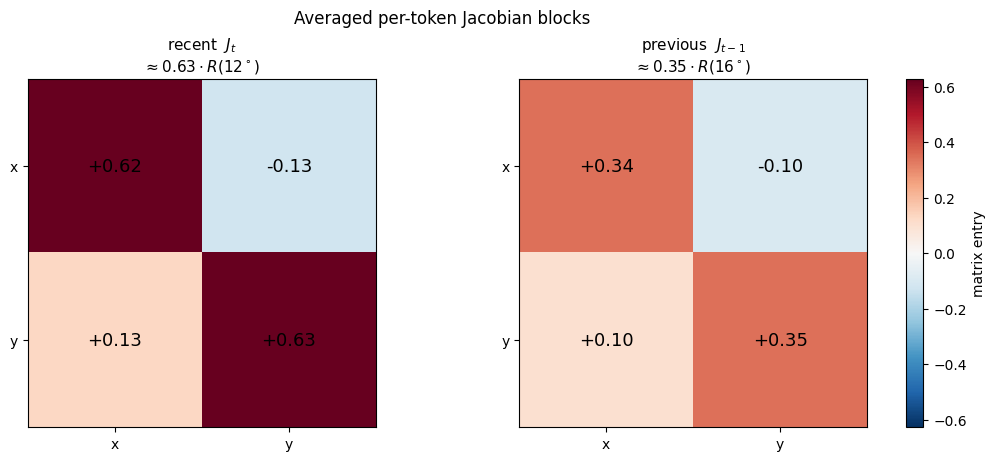

In [8]:
#| label: fig-jacobian-rotation
#| fig-cap: "Averaged per-token Jacobian blocks of the noisy bs=2 model. Both mean blocks are scaled rotation matrices (equal diagonals, equal-and-opposite off-diagonals), i.e. J ~ scale * R(angle) as annotated: a uniform scale composed with a small turn, rather than a forward push."
#| code-fold: true
from analysis.elm import rotation_decompose

mean_recent = all_blocks[:, T-1].mean(0)
mean_prev   = all_blocks[:, T-2].mean(0)
ds_r, a_r, ang_r, score_r = rotation_decompose(all_blocks[:, T-1])
ds_p, a_p, ang_p, score_p = rotation_decompose(all_blocks[:, T-2])
w_r    = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
radius = np.linalg.norm(w_r[:, T-1, :], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

vmax = max(abs(mean_recent).max(), abs(mean_prev).max())
sc_r, _, angm_r, _ = rotation_decompose(mean_recent)
sc_p, _, angm_p, _ = rotation_decompose(mean_prev)

for ax, M, name, sc, ang in [
    (axes[0], mean_recent, r'recent  $J_t$',       sc_r, angm_r),
    (axes[1], mean_prev,   r'previous  $J_{t-1}$', sc_p, angm_p)
]:
    im = ax.imshow(M, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['x', 'y']); ax.set_yticklabels(['x', 'y'])
    ax.set_title(f'{name}\n' +
                 rf'$\approx {float(sc):.2f}\cdot R({float(ang):.0f}^\circ)$',
                 fontsize=11)

fig.colorbar(im, ax=axes.tolist(), fraction=0.046, pad=0.04, label='matrix entry')
fig.suptitle('Averaged per-token Jacobian blocks', fontsize=12)
plt.show()

We can test this more formally by decomposing the linear transformations encoded
by these Jacobians. A $2\times2$ matrix has four degrees of freedom, which map
onto four basis matrices that are mutually orthogonal under the Frobenius inner
product $\langle A, B\rangle = \mathrm{tr}(A^\top B)$:

$$J = \underbrace{d_s \begin{bmatrix}1&0\\0&1\end{bmatrix}}_{\text{isotropic}} +
      \underbrace{a \begin{bmatrix}0&-1\\1&0\end{bmatrix}}_{\text{rotation}} +
      \underbrace{g_1 \begin{bmatrix}1&0\\0&-1\end{bmatrix}}_{\text{axis shear}} +
      \underbrace{g_2 \begin{bmatrix}0&1\\1&0\end{bmatrix}}_{\text{diagonal shear}}$$

The four coefficients are read directly off the matrix entries:

$$d_s = \frac{J_{00} + J_{11}}{2}, \quad
a   = \frac{J_{10} - J_{01}}{2}, \quad
g_1 = \frac{J_{00} - J_{11}}{2}, \quad
g_2 = \frac{J_{01} + J_{10}}{2}$$

Geometrically each component acts differently on a vector $\mathbf{r}$:

- **Isotropic** $d_s$: uniform scaling — pushes radially inward or outward
  equally in all directions.
- **Rotation** $a$: rotates $90°$ and scales — a pure turn with no stretching.
- **Axis shear** $g_1$: stretches along $x$ and compresses along $y$ (or vice
  versa) — deforms without rotating.
- **Diagonal shear** $g_2$: stretches along the $45°$ diagonal and compresses
  the perpendicular — a second independent shear mode.

With this full decomposition in hand, we calculate a "rotation score":

$$\frac{a^2}{a^2 + g_1^2 + g_2^2}$$

This score has a natural interpretation, it is the fraction of the *direction-changing*
action (everything except the isotropic scale) that is a clean rotation rather
than a shear distortion. A score near 1 means the block turns vectors without
deforming them while a score near 0 means shear dominates. If the model has learned
a rotation-based strategy we expect this score to be near 1 for both tokens,
shear near zero, and the generator coefficient $a$ to track the gravitational
acceleration magnitude across the orbit. 

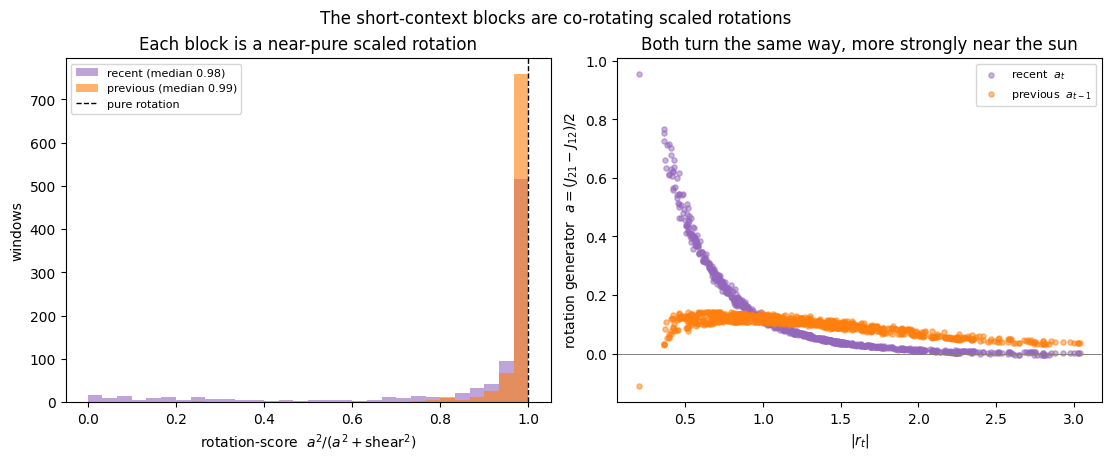

In [9]:
#| label: fig-rotation-generators
#| fig-cap: "Per-window rotation structure of the noisy bs=2 blocks. Left: the rotation-score a^2/(a^2 + shear^2) is near 1 for both tokens, so each individual block (not just the average) is a near-pure scaled rotation (shear negligible). Right: the rotation generator a = (J_21 - J_12)/2 - the signed strength of the block's sideways (perpendicular) push, which unlike the turn angle theta = atan2(a, c_s) is additive across blocks and stable where the isotropic scale c_s is small - is positive for both tokens (they co-rotate) and grows as the planet nears the sun. The recent block carries a clean radius-dependent turn; the previous block adds a small, nearly constant same-sign turn."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

# Left — rotation score histogram
ax = axes[0]
ax.hist(score_r, bins=30, range=(0, 1), color='tab:purple', alpha=0.6,
        label=f'recent (median {np.median(score_r):.2f})')
ax.hist(score_p, bins=30, range=(0, 1), color='tab:orange', alpha=0.6,
        label=f'previous (median {np.median(score_p):.2f})')
ax.axvline(1, color='k', ls='--', lw=1, label='pure rotation')
ax.set_xlabel(r'rotation-score  $a^2/(a^2+\mathrm{shear}^2)$')
ax.set_ylabel('windows')
ax.set_title('Each block is a near-pure scaled rotation')
ax.legend(fontsize=8, loc='upper left')

# Right — rotation GENERATOR a = (J21 - J12)/2, vs radius
ax = axes[1]
ax.axhline(0, color='gray', lw=0.7)
ax.scatter(radius, a_r, s=14, alpha=0.5, color='tab:purple', label=r'recent  $a_t$')
ax.scatter(radius, a_p, s=14, alpha=0.5, color='tab:orange', label=r'previous  $a_{t-1}$')
ax.set_xlabel(r'$|r_t|$')
ax.set_ylabel(r'rotation generator  $a=(J_{21}-J_{12})/2$')
ax.set_title('Both turn the same way, more strongly near the sun')
ax.legend(fontsize=8)

fig.suptitle('The short-context blocks are co-rotating scaled rotations', fontsize=12)
plt.show()

@fig-rotation-generators (left) shows the rotation-score sits near 1 for both tokens implying each block is a near-pure scaled rotation, not a shear or reflection. Moreover, the generator *a* scales with radius, especially for the more recent token, suggesting that the model might be adjusting the rotation to match gravitational force. The exact nature scaled rotation will depend both on the generator and isotropic components (and how their effects are combined across the two tokens). To avoid this complexity we next use a behavioral test to further test the rotation hypothesis. 

### The noisy short-context model runs a local circular-orbit heuristic

Inspecting the Jacobians suggests the model turns $\mathbf r_t$, but what sets the angle? Kepler's second law (a planet sweeps equal areas in equal times) fixes the per-step angle of a real orbit to $\Delta\theta = L_z\,\Delta t / r^2$, where $L_z = x\,\dot y - y\,\dot x$ is the angular momentum, the conserved rate at which the position vector sweeps out area. So the true angle should grow like $1/r^2$ (faster near the sun) but also scale with $L_z$ (which differs from orbit to orbit). Our sequences carry positions and not velocities, so we estimate the numerator of that expression directly from the in-window displacement, $L_z\,\Delta t \approx \mathbf r_t \times (\mathbf r_t - \mathbf r_{t-1})$ — the quantity that actually sets the per-step angle. Below we use a behavioral test to compare the model's per-step rotation against both, and against the radial in-and-out motion a real orbit undergoes.

In [10]:
#| code-fold: true
#| output: false
# Behavioural rotation statistics over many cheap forward passes.
behav = NT.rotation_behavioral(model, BLOCK_SIZE, N_WINDOWS_BEH, seed=SEED, offset=OFFSET)


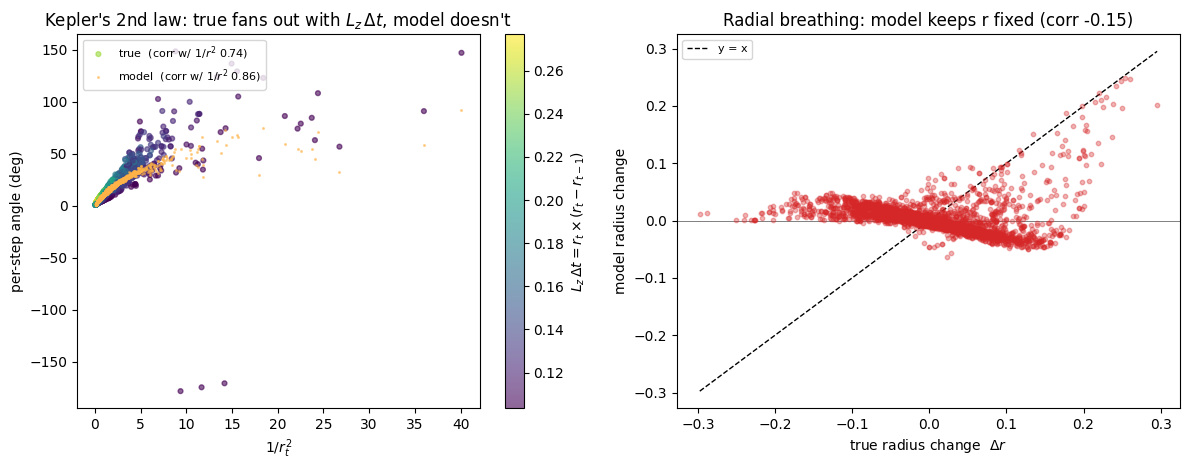

In [11]:
#| label: fig-kepler2
#| fig-cap: "Left: per-step rotation angle vs 1/r^2. Points are coloured by L_z*dt = r_t x (r_t - r_{t-1}), the numerator of the per-step angle in Kepler's 2nd law (dtheta = L_z*dt / r^2), estimated from the in-window displacement because the sequences carry positions rather than velocities. The true orbit's angle fans out with L_z*dt, whereas the model's angle (orange) is a tight function of 1/r^2 alone — it ignores angular momentum. Right: the true per-step radius change vs the model's; the model keeps the radius almost fixed, ignoring the orbit's radial breathing."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left — Kepler's 2nd law: per-step angle vs 1/r^2
ax = axes[0]
Lz_dt, inv_r2 = behav['Lz_dt'], behav['inv_r2']
at, am = np.degrees(behav['ang_true']), np.degrees(behav['ang_model'])
vlo, vhi = float(np.nanpercentile(Lz_dt, 2)), float(np.nanpercentile(Lz_dt, 98))
sc = ax.scatter(inv_r2, at, s=12, alpha=0.6, c=Lz_dt, cmap='viridis', vmin=vlo, vmax=vhi,
                label=f"true  (corr w/ $1/r^2$ {behav['kepler2_corr_true']:.2f})")
ax.scatter(inv_r2, am, s=6, alpha=0.5, color='#FFB347', marker='.',
           label=f"model  (corr w/ $1/r^2$ {behav['kepler2_corr_model']:.2f})")
cb = fig.colorbar(sc, ax=ax); cb.set_label(r'$L_z\,\Delta t = r_t \times (r_t - r_{t-1})$')
ax.set_xlabel(r'$1/r_t^2$'); ax.set_ylabel('per-step angle (deg)')
ax.set_title(r"Kepler's 2nd law: true fans out with $L_z\,\Delta t$, model doesn't")
ax.legend(fontsize=8, loc='upper left')

# Right — radial breathing
ax = axes[1]
dtr, dmr = behav['dr_true'], behav['dr_model']
lo, hi = float(min(dtr.min(), dmr.min())), float(max(dtr.max(), dmr.max()))
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.axhline(0, color='gray', lw=0.7, zorder=1)
ax.scatter(dtr, dmr, s=10, alpha=0.35, color='tab:red', zorder=2)
ax.set_xlabel(r'true radius change  $\Delta r$'); ax.set_ylabel(r'model radius change')
ax.set_title(f"Radial breathing: model keeps r fixed (corr {behav['dr_corr']:.2f})")
ax.legend(fontsize=8)

fig.tight_layout(); plt.show()


Two things stand out in @fig-kepler2. The model's rotation angle does indeed monotonically grow with $1/r^2$ (i.e. it speeds up near the sun) but unlike the true orbit it is a single tight curve which ignores angular momentum (the orange points show little vertical spread, while the true points fan out by colour). Moreose, there is no evidence of radial breathing, the model barely changes the radius step-to-step (mostly encoding a small bias towards shrinking the radius), roughly keeping the planet on a circular orbit. Together these results suggest the model isn't tracking the real orbit, instead it treats each step as if the planet were on a local circular orbit of the current radius. A circular orbit at radius $r$ sweeps $\Delta\theta = \Delta t / r^{3/2}$ per step (with $GM=1$). If that is the heuristic, the model's rotation should match this curve, a prediction we test below.


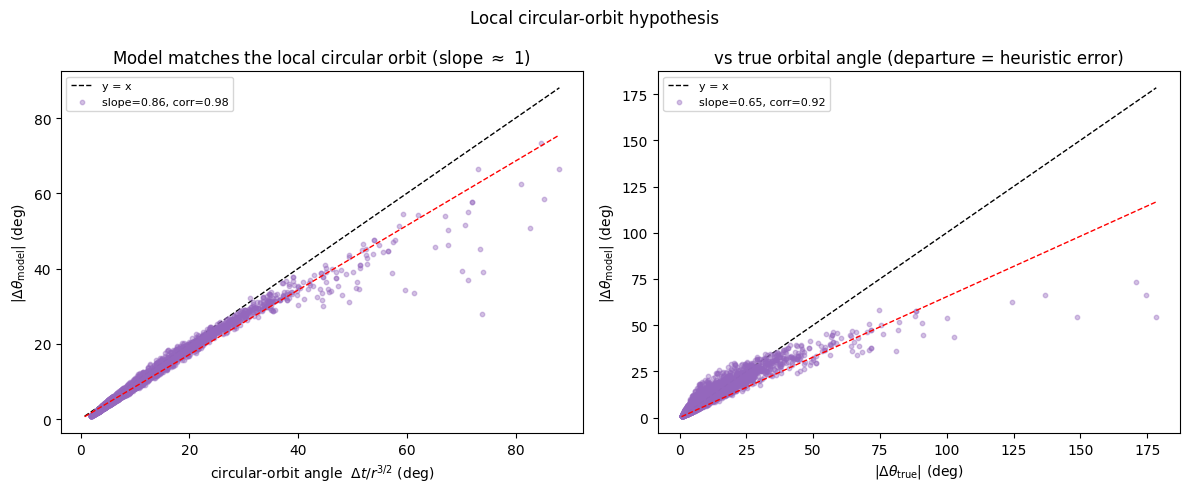

In [12]:
#| label: fig-circular
#| fig-cap: "Left: model per-step rotation angle vs the angle a circular orbit of the same radius sweeps (dt / r^{3/2}); the tight proportionality (slope 0.86, corr 0.98) shows the model applies the local-circular-orbit rotation, lagging it by ~14%. Right: model angle vs the true orbital angle; departures from y=x are the heuristic's error on eccentric orbits. (Windows with a circular prediction > 90 deg are dropped.)"
#| code-fold: true
r_t          = behav['inv_r2'] ** (-0.5)
ang_circular = np.degrees(DT / r_t**1.5)
am_abs, at_abs = np.abs(np.degrees(behav['ang_model'])), np.abs(np.degrees(behav['ang_true']))

mask = ang_circular < 90.0
ang_c_m, am_m, at_m = ang_circular[mask], am_abs[mask], at_abs[mask]
corr_m,   slope_m   = np.corrcoef(ang_c_m, am_m)[0, 1], np.polyfit(ang_c_m, am_m, 1)[0]
corr_beh, slope_beh = np.corrcoef(at_m,   am_m)[0, 1], np.polyfit(at_m,   am_m, 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
lo, hi = float(min(ang_c_m.min(), am_m.min())), float(max(ang_c_m.max(), am_m.max()))
xs = np.linspace(lo, hi, 100)
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(ang_c_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'slope={slope_m:.2f}, corr={corr_m:.2f}')
ax.plot(xs, slope_m * xs, 'r--', lw=1)
ax.set_xlabel(r'circular-orbit angle  $\Delta t / r^{3/2}$ (deg)')
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)')
ax.set_title(r'Model matches the local circular orbit (slope $\approx$ 1)')
ax.legend(fontsize=8)

ax = axes[1]
lo2, hi2 = float(min(at_m.min(), am_m.min())), float(max(at_m.max(), am_m.max()))
xs2 = np.linspace(lo2, hi2, 100)
ax.plot([lo2, hi2], [lo2, hi2], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(at_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'slope={slope_beh:.2f}, corr={corr_beh:.2f}')
ax.plot(xs2, slope_beh * xs2, 'r--', lw=1)
ax.set_xlabel(r'$|\Delta\theta_{\rm true}|$ (deg)')
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)')
ax.set_title('vs true orbital angle (departure = heuristic error)')
ax.legend(fontsize=8)

fig.suptitle('Local circular-orbit hypothesis', fontsize=12)
fig.tight_layout(); plt.show()



@fig-circular confirms this. The model's rotation angle tracks the circular-orbit prediction $\Delta t / r^{3/2}$ closely (left; corr $= 0.98$, $R^2 = 0.96$), deviating only at extreme angles (likely near perihelion where large jumps in orbital position happen relative to time-slices used in our simulations). The fitted slope is $0.86$ rather than exactly $1$, so the model applies the local-circular-orbit rotation but lags it by roughly $14\%$. Compared to the true orbit angle (right), the model has a significantly reduced scaling (slope $= 0.65$) demonstrating that a local circular orbit matches the model's behaviour much closer than a properly fit elliptical orbit prediction. 

So the noise-robust short-context model has almost certainly not learned Newtonian gravity. Instead, it has learned a local circular-orbit heuristic: rotate the most recent position by approximately the angle a circular orbit of that radius would sweep, and hold the radius mostly fixed. This is a smooth approximation, it captures the $r^{-3/2}$ angular speed-up of a circular orbit but discards angular momentum and radial dynamics. This solution works in the context of the training task because the model is only ever trained to predict the position of 1 future timepoint (i.e. a rollout loss is not used), so a heuristic for a small time-step can work decently well. The apparent noise-tolerance of this heuristic is also a key as to why the model didn't (and probably *couldn't*) learn a Newtonian integrator, since solutions like Verlet will massively amplify input error. Consequently in the next section we re-train a version of this model with no input noise to check whether the correct world model will emerge in this setting. 

## Without training noise, the model learns Newton

The noisy short-context model settled for a smooth, noise-robust heuristic. To check whether removing input noise during training might allow the correct world model to be learned, we repeat our analyses on a noiseless bs=2 model (`noise_scale = 0.0`). Freed from having to tolerate corrupted context, this model should be able to afford the sharp finite-difference computation of a genuine Newtonian force integrator.


In [13]:
#| code-fold: true
#| output: false
# Switch to the NOISELESS model (noise_scale = 0.0) and recompute its Jacobian blocks.
CKPT_BS2_NL = f'{CHECKPOINT_DIR}/model_block_size_{BLOCK_SIZE}_num_trajectories_{NUM_TRAJ}_noise_scale_0.0.pt'
with contextlib.redirect_stdout(io.StringIO()):
    model_noiseless, _ = load_from_checkpoint(CKPT_BS2_NL, device='cpu'); model_noiseless.eval()
    all_blocks, coeffs, content, positional, radius, recon_err_max = NT.collect_terms(
        model_noiseless, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]; D = all_blocks.shape[-1]


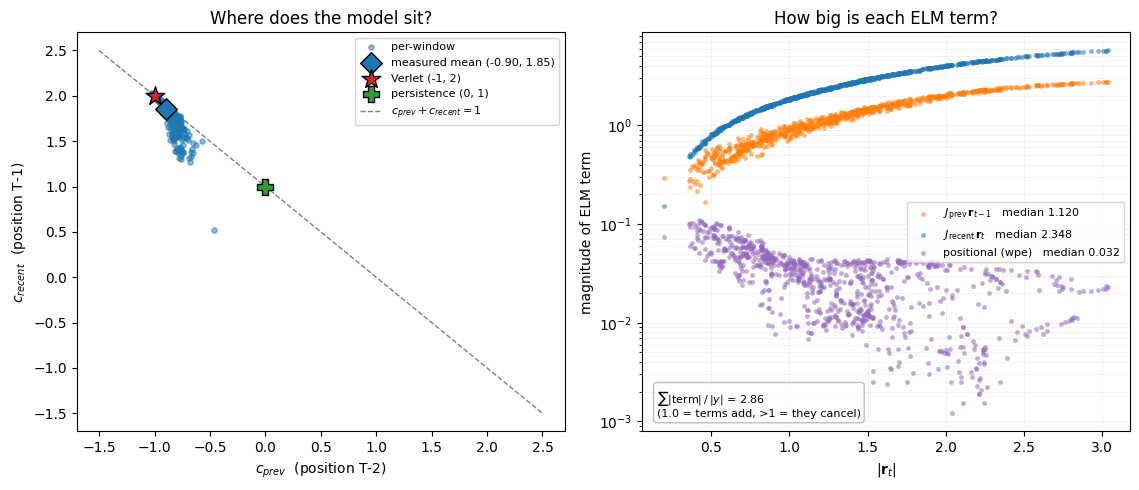

In [14]:
#| label: fig-verlet-noiseless
#| fig-cap: "Left: isotropic Jacobian coefficients of the noiseless bs=2 model in (c_prev, c_recent) space (c_s = tr(J_s)/D). Unlike the noisy model, the per-window points and their mean (~ -0.9, +1.85) sit essentially on the inertial point (-1, 2) rather than the persistence line - the noiseless model extrapolates forward like a genuine second-order (Verlet) integrator instead of averaging its two inputs. Right: the size of every term in the ELM sum for the same windows (log scale). Here the two content terms are large and opposing - a prediction of magnitude ~1.24 built from terms of ~1.12 and ~2.35 (sum of magnitudes / |y| = 2.86) - the signature of extrapolation rather than averaging. The positional (wpe) term is 2.3% of the prediction; it is small against the inertial coefficients measured here, but not against the much smaller deviation from inertia, where it is comparable to the gravitational kick itself (@fig-kick-terms)."
#| code-fold: true
positions = np.arange(T)
c_mean, c_std = coeffs.mean(0), coeffs.std(0)

target = np.zeros(T); target[T-1] = 2.0; target[T-2] = -1.0

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
ax = axes[0]

c_prev, c_recent = coeffs[:, T-2], coeffs[:, T-1]
ax.scatter(c_prev, c_recent, s=14, alpha=0.5, color='tab:blue', label='per-window', zorder=2)
ax.scatter([c_prev.mean()], [c_recent.mean()], s=120, marker='D', color='tab:blue', edgecolor='k',
           label=f'measured mean ({c_prev.mean():.2f}, {c_recent.mean():.2f})', zorder=4)
ax.scatter([-1], [2], s=200, marker='*', color='tab:red', edgecolor='k', label='Verlet (-1, 2)', zorder=5)
ax.scatter([0], [1], s=120, marker='P', color='tab:green', edgecolor='k', label='persistence (0, 1)', zorder=4)
lo = min(-1.5, float(c_prev.min())); hi = max(2.5, float(c_recent.max()))
xs = np.linspace(lo, hi, 50)
ax.plot(xs, 1 - xs, ls='--', color='gray', lw=1, label=r'$c_{prev}+c_{recent}=1$', zorder=1)
ax.set_xlabel(r'$c_{prev}$  (position T-2)')
ax.set_ylabel(r'$c_{recent}$  (position T-1)')
ax.set_title('Where does the model sit?')
ax.legend(fontsize=8, loc='best')

# Right panel: how big is each term in the ELM sum?  The coefficient analysis on
# the left uses the content Jacobians only, so show what the omitted positional
# term is worth alongside them.
NT.plot_term_magnitudes(axes[1], content, positional, radius)
axes[1].set_title('How big is each ELM term?')

fig.tight_layout()
plt.show()


The contrast with the noisy model is stark. @fig-verlet-noiseless shows the noiseless model's isotropic coefficients at $(c_{\text{prev}}, c_{\text{recent}}) \approx (-0.9, +1.85)$, much closer to the inertial point $(-1, 2)$ than the noisy model. This model seems to extrapolate forward like a genuine second-order integrator, rather than blending its two inputs. The relative magnitudes of the content positional terms is also subtly altered in a manner that is consistent with Verlet integration. There is a consistent difference in the weighing of the two input coordinates that is relatively radius invariant, the most recent term being weighed consistently more than the previous token reflective of the structure imparted by the isotropic coefficients which track the inertial point $(-1, 2)$. Similar to the noisy model, the positional terms are relatively weak in magnitude although we will show later that they do play an important contribution to the final prediction. 

The physics that makes should make this model explicitly Newtonian rather than merely inertial will live in the residual from the inertial point. In the next step we verify behaviourally that this correction is exactly the Newtonian gravitational kick $-\Delta t^2\,\mathbf r_t/|\mathbf r_t|^3$, and then examine how that residual is organised across the model’s two input tokens and positional embedding terms.

### The deviation from inertia is Newtonian gravity

As a first step we behaviourally test (with no reference to the detached Jacobian) whether the model's non-inertial output actually captures Newtonian gravity. From the model's own second difference, $\mathbf a_{\rm eff} = (\hat{\mathbf r}_{t+1} - 2\mathbf r_t + \mathbf r_{t-1})/\Delta t^2$, a genuine force integrator would give $\mathbf a_{\rm eff} = -\mathbf r_t/|\mathbf r_t|^3$ ($GM=1$).


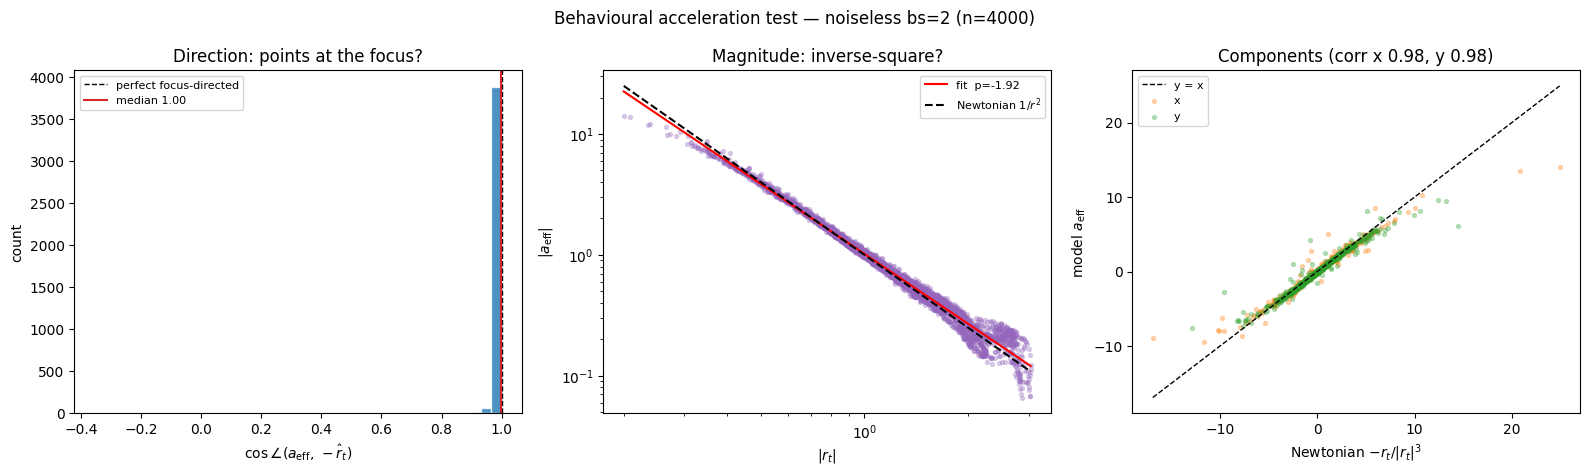

In [15]:
#| label: fig-newton-behavioral
#| fig-cap: "Attribution-free test that the noiseless model's non-inertial output is Newtonian gravity. a_eff = (r_hat - 2 r_t + r_prev)/dt^2. Left: a_eff points at the sun (cos ~ 0.999). Middle: |a_eff| ~ 1/r^1.9 (Newtonian -2), GM_est ~ 1.02. Right: components match -r_t/|r_t|^3 (corr ~ 0.98)."
#| code-fold: true
# ── Behavioural acceleration test: is the model's non-inertial output Newtonian gravity? ──
# Attribution-free — uses the second difference of the model's OWN prediction, so it's
# invariant to how gravity is split across J_recent / J_prev:
#   a_eff = (r_hat_{t+1} - 2 r_t + r_{t-1}) / dt^2     (Verlet: a_eff = -r_t/|r_t|^3, GM=1)
# Tests (1) does a_eff point at the focus?  (2) does |a_eff| ~ 1/r^2?
N_ACC = 4000
mdl   = model_noiseless                      # the noiseless (Verlet-like) model

w = NT.sample_orbit_windows(BLOCK_SIZE, N_ACC, seed=SEED, offset=OFFSET)   # (n,2,2)
r_prev, r_t = w[:, -2, :], w[:, -1, :]

mdtype = next(mdl.parameters()).dtype
with torch.no_grad():
    pred = mdl(torch.tensor(w).to(mdtype))[0][:, -1, :].double().numpy()   # (n,2)

a_eff  = (pred - 2*r_t + r_prev) / DT**2      # model's effective acceleration
r      = np.linalg.norm(r_t, axis=1)
a_true = -r_t / r[:, None]**3                 # Newtonian gravity at r_t (GM=1)

# (1) direction: cos between measured and Newtonian (focus-directed) acceleration
cos_dir = (a_eff*a_true).sum(1) / (np.linalg.norm(a_eff,axis=1)*np.linalg.norm(a_true,axis=1) + 1e-30)
# (2) magnitude scaling: |a_eff| ~ r^p; Newtonian p=-2, intercept -> GM
mag = np.linalg.norm(a_eff, axis=1)
slope, intercept = np.polyfit(np.log(r), np.log(mag), 1)
GM_est = np.exp(intercept)
# (3) component-wise agreement
corr_x = np.corrcoef(a_eff[:,0], a_true[:,0])[0,1]
corr_y = np.corrcoef(a_eff[:,1], a_true[:,1])[0,1]

# ── figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax = axes[0]
ax.hist(cos_dir, bins=40, color='tab:blue', alpha=0.8, edgecolor='white')
ax.axvline(1, color='k', ls='--', lw=1, label='perfect focus-directed')
ax.axvline(np.median(cos_dir), color='tab:red', lw=1.5, label=f'median {np.median(cos_dir):.2f}')
ax.set_xlabel(r'$\cos\angle(a_{\rm eff},\,-\hat r_t)$'); ax.set_ylabel('count')
ax.set_title('Direction: points at the focus?'); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(r, mag, s=8, alpha=0.3, color='tab:purple')
rr = np.linspace(r.min(), r.max(), 100)
ax.plot(rr, GM_est*rr**slope, 'r-',  lw=1.5, label=f'fit  p={slope:.2f}')
ax.plot(rr, rr**-2.0,         'k--', lw=1.5, label=r'Newtonian $1/r^2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$|r_t|$'); ax.set_ylabel(r'$|a_{\rm eff}|$')
ax.set_title('Magnitude: inverse-square?'); ax.legend(fontsize=8)

ax = axes[2]
lo = float(min(a_eff.min(), a_true.min())); hi = float(max(a_eff.max(), a_true.max()))
ax.plot([lo,hi],[lo,hi],'k--',lw=1,label='y = x')
ax.scatter(a_true[:,0], a_eff[:,0], s=8, alpha=0.3, color='tab:orange', label='x')
ax.scatter(a_true[:,1], a_eff[:,1], s=8, alpha=0.3, color='tab:green',  label='y')
ax.set_xlabel(r'Newtonian $-r_t/|r_t|^3$'); ax.set_ylabel(r'model $a_{\rm eff}$')
ax.set_title(f'Components (corr x {corr_x:.2f}, y {corr_y:.2f})'); ax.legend(fontsize=8)

fig.suptitle(f'Behavioural acceleration test — noiseless bs={BLOCK_SIZE} (n={N_ACC})', fontsize=12)
fig.tight_layout(); plt.show()

@fig-newton-behavioral confirms it: the model's effective acceleration points at the sun ($\cos \approx 0.999$), scales inverse-square ($|\mathbf a_{\rm eff}| \sim r^{-1.9}$ vs. Newtonian $r^{-2}$), and matches gravity component-by-component ($\mathrm{corr}\approx 0.98$). Unlike the noisy model's circular heuristic, the noiseless model has learned the true $1/r^2$ force satisfying our requirement for having learned a Newtonian world model. Next, we use the Jacobian to ask how this gravitational kick is computed by the model.

### What supplies the gravitational kick

The behavioural test tells us that the noiseless model's departure from inertial coasting is Newtonian gravity. ELM however gives us the ability to go a step further and ask *how* that kick is produced by inspecting the terms the model actually adds up. Subtracting Verlet's inertial part from the ELM identity leaves three:

$$\underbrace{\hat{\mathbf r}_{t+1} - (2\mathbf r_t - \mathbf r_{t-1})}_{\text{deviation from inertia}} \;=\; \underbrace{\mathrm{d}J_t\,\mathbf r_t \;+\; \mathrm{d}J_{t-1}\,\mathbf r_{t-1}}_{\text{content residual}} \;+\; \underbrace{\mathbf P}_{\text{positional}}$$

with $\mathrm{d}J_t = J_t - 2I$, $\mathrm{d}J_{t-1} = J_{t-1} + I$, and $\mathbf P = \sum_s J_{h,s}\,\mathrm{wpe}[s]$. One term per input token plus the positional one: this split is forced by the architecture rather than chosen by us.

Two features of the identity matter for what follows. First, it is a sum of vectors. The $\mathrm{d}J$ blocks are *operators*, and they only become contributions once they act on their inputs, so the three terms have to be compared as the products $\mathrm{d}J\,\mathbf r$ rather than as matrices. Second, the positional term is not negligible at this scale. It is a couple of percent of the prediction (@fig-verlet-noiseless, right), but the deviation from inertia is itself some forty times smaller than the prediction, and measured against that quantity $\mathbf P$ is comparable in size to the gravitational kick.

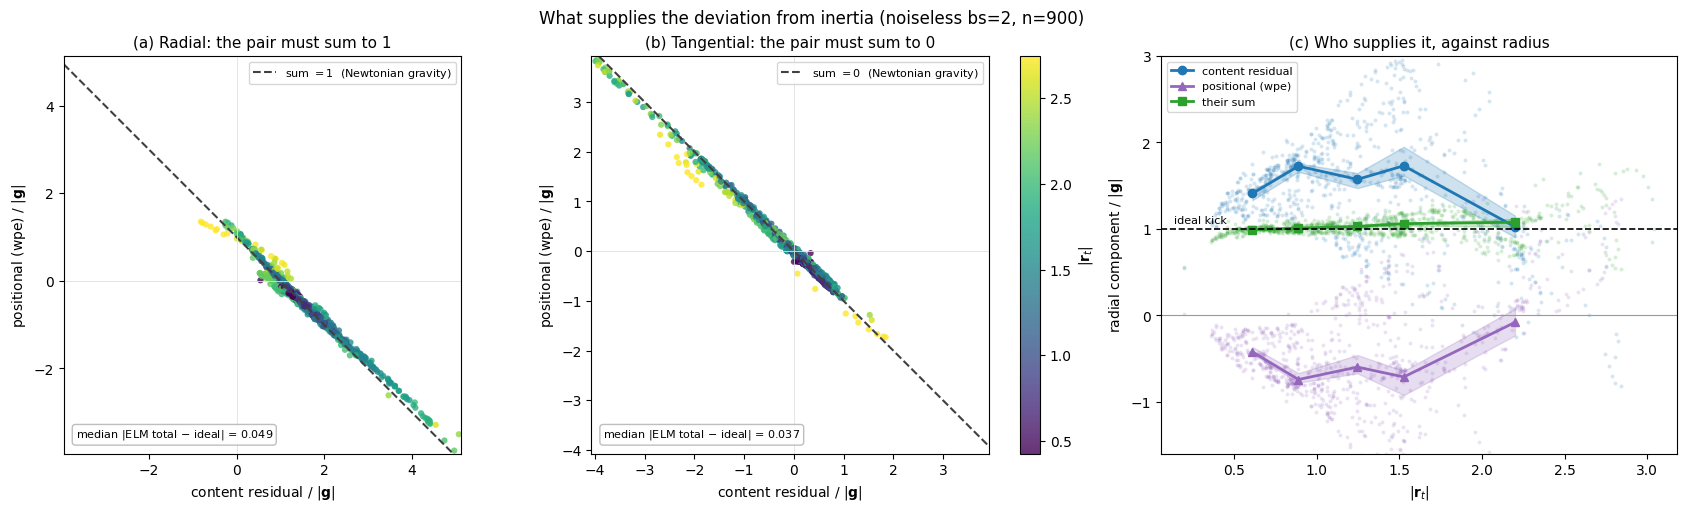

power law of each term, |term| ~ r^p:      content -1.66   positional -1.14   sum -1.93   ideal gravity -2.00
median deviation from the constraint line:  radial 0.049   tangential 0.037
radial supply by radius bin (median [95% CI]):
  content residual   r=0.61: +1.41[+1.33,+1.44]  r=0.89: +1.73[+1.66,+1.76]  r=1.25: +1.57[+1.47,+1.65]  r=1.53: +1.73[+1.62,+1.95]  r=2.20: +1.03[+0.90,+1.15]
  positional (wpe)   r=0.61: -0.42[-0.45,-0.36]  r=0.89: -0.74[-0.78,-0.67]  r=1.25: -0.60[-0.67,-0.46]  r=1.53: -0.71[-0.92,-0.64]  r=2.20: -0.08[-0.23,+0.08]
  their sum          r=0.61: +0.99[+0.98,+1.00]  r=0.89: +1.01[+1.00,+1.02]  r=1.25: +1.03[+1.02,+1.04]  r=1.53: +1.06[+1.04,+1.07]  r=2.20: +1.08[+1.02,+1.12]


In [16]:
#| label: fig-kick-terms
#| fig-cap: "How the noiseless model's deviation from inertial coasting is built from the three vector terms the ELM identity actually contains: the two content residuals dJ_t r_t and dJ_(t-1) r_(t-1) (shown summed as the content residual) and the positional (wpe) term P. Each panel takes one component of the deviation, resolved in that window's own gravity frame - (a) radial, along the ideal kick and so toward the star, and (b) tangential, perpendicular to it - and plots the positional contribution against the content one in units of |g|. Reproducing gravity requires the radial pair to sum to 1 and the tangential pair to sum to 0, so each component must fall on a line of slope -1 (dashed). Both do, over more than an order of magnitude. Three features of these panels say different things. Where along its line a point sits is the result: it is how the labour is divided between the two terms, and many divisions are compatible with the same total - (1, 0), (0.5, 0.5) and (3, -2) all reproduce gravity - so which one the network uses is not derivable from its behaviour. That the lines sit at 1 and 0 is a consistency check: the ELM attribution and the behavioural measurement of @fig-newton-behavioral reach the same total by different routes, one summing attributed Jacobian terms and the other differencing the model's output. The slope carries nothing - the two terms sum to a quantity far smaller than either of them, so a slope near -1 follows by construction whatever the model has learned. Points are coloured by |r_t|: both terms grow relative to |g| as the planet moves outward, because |g| falls as r^-2 while the content residual falls as r^-1.66 and the positional term only as r^-1.14. The sum nonetheless stays on the line at every radius, which is the inverse-square law restated - and its fitted exponent, r^-1.93, is the same quantity @fig-newton-behavioral measures behaviourally as r^-1.92. (c) The radial division plotted against radius directly, with medians over five quantile bins and a 95% bootstrap CI of the median. Wherever r is below about 1.8 the content residual oversupplies the radial kick by 40-70% (medians 1.41 to 1.73, every interval clear of 1) and the positional term subtracts a matching -0.42 to -0.74. In the outermost bin the arrangement lapses: the content residual alone supplies the kick (1.03, CI [0.90, 1.15], consistent with exactly 1) and the positional term falls to -0.08, CI [-0.23, +0.08], indistinguishable from zero. The sum tracks 1 throughout to within a few percent (0.99 to 1.08), the small overshoot growing outward."
#| code-fold: true
from analysis.elm import kick_terms, plot_kick_terms

w_kick = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
assert len(w_kick) == len(all_blocks), f"{len(w_kick)} vs {len(all_blocks)}"

# The ELM identity is exact, so the three terms must reproduce the model's own
# deviation from inertial coasting. Check that rather than trust it -- it catches
# any index or sign slip in the dJ products.
_kt = kick_terms(content, positional, w_kick, DT)
_mdtype = next(model_noiseless.parameters()).dtype
with torch.no_grad():
    _pred = model_noiseless(torch.tensor(w_kick).to(_mdtype))[0][:, -1, :].double().numpy()
_inertia = 2 * w_kick[:, T - 1, :] - w_kick[:, T - 2, :]
assert np.abs(_kt['total'] - (_pred - _inertia)).max() < 1e-6

fig, axes = plt.subplots(1, 3, figsize=(17.4, 5.0), constrained_layout=True)
kick = plot_kick_terms(axes, content, positional, w_kick, DT)
fig.suptitle(f'What supplies the deviation from inertia (noiseless bs={BLOCK_SIZE}, n={N_WINDOWS})',
             fontsize=12)
plt.show()

print('power law of each term, |term| ~ r^p:      '
      + '   '.join(f'{k} {v:+.2f}' for k, v in kick['exponent'].items()))
print('median deviation from the constraint line:  '
      + '   '.join(f'{k} {v:.3f}' for k, v in kick['line_deviation'].items()))
_rp = kick['radial_profile']
print('radial supply by radius bin (median [95% CI]):')
for _k in ('content residual', 'positional (wpe)', 'their sum'):
    _p = _rp[_k]
    print(f'  {_k:18s} ' + '  '.join(
        f'r={r_:.2f}: {m:+.2f}[{l:+.2f},{h:+.2f}]'
        for r_, m, l, h in zip(_p['r'], _p['median'], _p['lo'], _p['hi'])))

@fig-kick-terms shows that both the content residuals and the positional embeddings are required to reconstruct the correct gravitational pull. Each panel resolves one component of the deviation in that window's own gravity frame, radial along the ideal kick (toward the star), and tangential (perpendicular error) and plots what each ELM term supplies. Gravity requires the radial pair to sum to $1$ and the tangential pair to sum to $0$, which puts each component on a line of slope $-1$; the dashed lines are those two constraints. Both components sit on their line across more than an order of magnitude, demonstrating how the combination of all terms is needed to capture Newtonian gravity. 

Radially the content residual on average oversupplies roughly $1.5\times$ the required sunward pull which is countered by the positional term trimming the overshoot. Tangentially, where gravity should contribute nothing at all, each term carries a sizeable sideways push whose direction varies from window to window, and the two annihilate. Panel (c) plots the radial division against radius directly.  Wherever $r<1$ the content residual consistently oversupplies the gravitational kick which is countered by the positional embedding terms. At larger radii however ($r>1$) there is more variability in the contributions of the two types of terms, with the positional embedding at times contributing positively to boost an underpowered content residual kick, and in even rarer cases where the content residual contributes a negative (outward) radial pull. 

Three features of these panels carry different weight, and it is worth separating them. The *position along* each line is the result. It records how the labour is divided between the two terms, and the division is not unique: $(1, 0)$, $(0.5, 0.5)$ and $(3, -2)$ all reproduce gravity equally well, so which one the network settles on is a fact about how the computation is laid out across the token and positional pathways rather than something recoverable from its behaviour. That the *lines sit* at $1$ and $0$ is a consistency check rather than a new finding: the attribution route used here and the behavioural route of @fig-newton-behavioral arrive at the same total by different means, one summing Jacobian terms and the other differencing the model's output, so their agreement is evidence that the decomposition is faithful. The *slope*, finally, carries no information at all — because the two terms sum to something far smaller than either of them, a slope near $-1$ follows by construction, whatever the model has learned.

So the gravitational kick is assembled by cancellation across the positional and content residual components. In the next section we unpack the nature of the two residual Jacobian matrices to demonstrate how they themselevs act on the input coordinates to produce their contribution to the gravitational kick described here. 

### The structure of the two content residual operators

With the division of labour established, we can ask what the two content operators look like. The objects are the Jacobian deviations from inertia, $\mathrm{d}J_t = J_t - 2I$ and $\mathrm{d}J_{t-1} = J_{t-1} + I$. Note the change of footing: what follows characterises these two *operators*, not the net kick, which @fig-kick-terms showed is what survives after they cancel and the positional term completes the remainder.

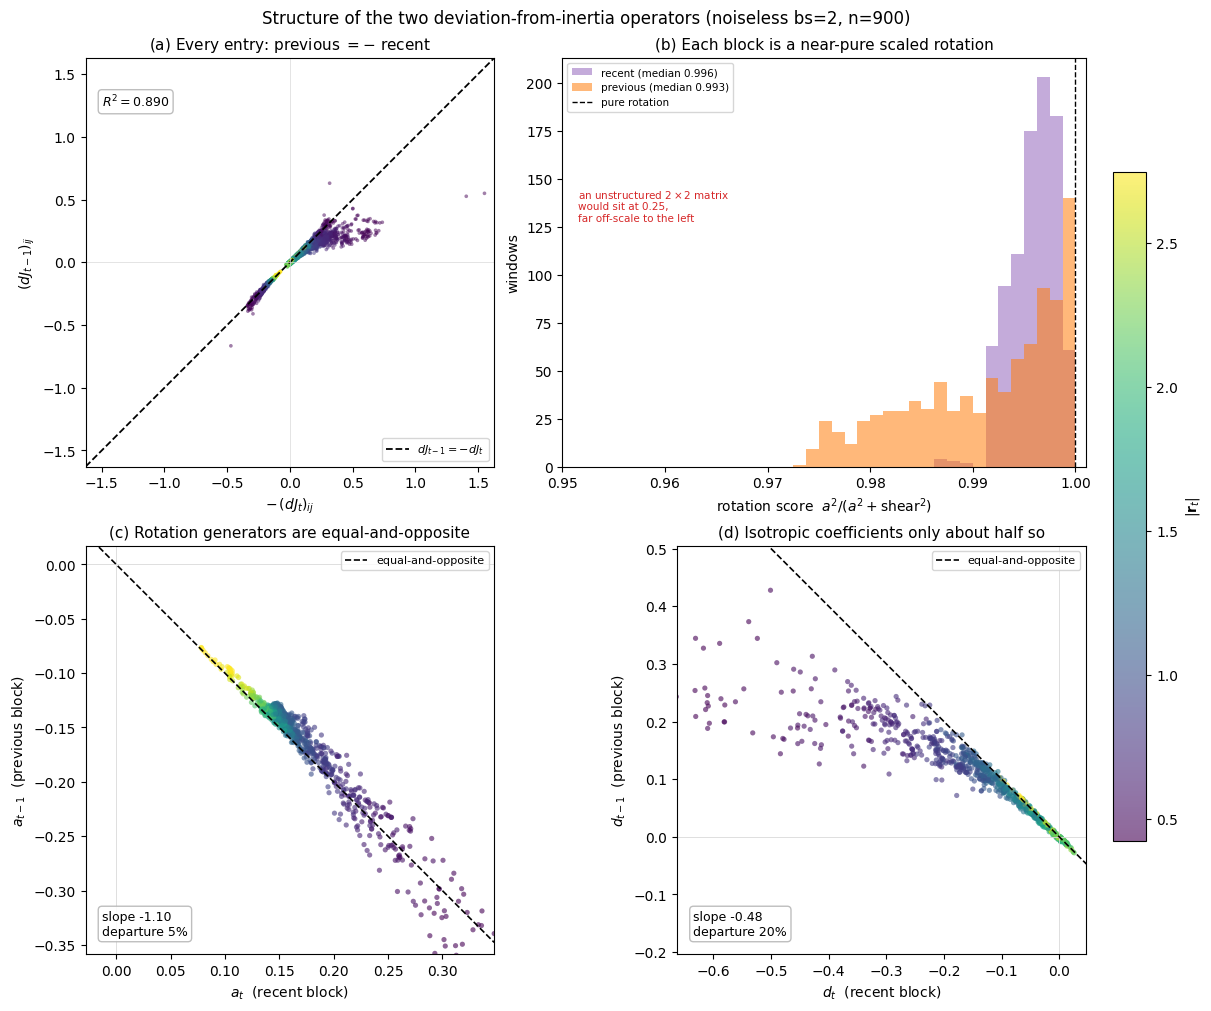

negation:  entry-wise R^2 0.890   per-window failure 0.133
rotation score:  recent 0.996   previous 0.993   unstructured 2x2 0.253
equal-and-opposite:  a slope -1.10 (departure 5%)   d slope -0.48 (departure 20%)


In [17]:
#| label: fig-residual-structure
#| fig-cap: "Invariant structure of the two deviation-from-inertia operators, dJ_t = J_t - 2I and dJ_(t-1) = J_(t-1) + I, for the noiseless short-context model; all panels coloured by |r_t|. (a) Every matrix entry of the previous block against the negative of the corresponding recent-block entry: the two are near-negations, entry-wise R^2 = 0.89, with a per-window failure ||dJ_t + dJ_(t-1)|| / ||dJ_t|| of 0.13 that grows toward small r. (b) The rotation score a^2/(a^2 + shear^2) of each block, on a zoomed axis because every value exceeds 0.97; an unstructured 2x2 matrix would sit near 0.25. Each block is therefore a scaled rotation - an isotropic scale d composed with a rotation generator a - with negligible shear. (c), (d) Those two coefficients, previous block against recent. They behave differently: the rotation generator is equal-and-opposite (fitted slope -1.10, departing by 5 percent per window) while the isotropic coefficient is only about half so (slope -0.48, 20 percent), its departure worst at small radius. Each panel is scaled snugly to its own cloud, so the slope is annotated rather than left to the eye. Everything here is rotation-invariant or a matrix identity, so it describes the operators independently of any choice of axes - and it describes the operators only. dJ_(t-1) acts on r_(t-1), some eight times longer than the step r_t - r_(t-1), so the residual left by the imperfect negation contributes to the correction on a par with the difference term; the negation does not license a claim that the correction is a function of the velocity."
#| code-fold: true
from analysis.elm import plot_residual_structure

w_match = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
assert len(w_match) == len(all_blocks), f"{len(w_match)} vs {len(all_blocks)}"

fig, axes = plt.subplots(2, 2, figsize=(12.4, 10.0), constrained_layout=True)
st = plot_residual_structure(axes, all_blocks, w_match)
fig.suptitle(f'Structure of the two deviation-from-inertia operators '
             f'(noiseless bs={BLOCK_SIZE}, n={N_WINDOWS})', fontsize=12)
plt.show()

print(f"negation:  entry-wise R^2 {st['r2']:.3f}   "
      f"per-window failure {np.median(st['fail']):.3f}")
print(f"rotation score:  recent {np.median(st['score_r']):.3f}   "
      f"previous {np.median(st['score_p']):.3f}   "
      f"unstructured 2x2 {st['score_random']:.3f}")
print(f"equal-and-opposite:  a slope {st['slope_a']:+.2f} (departure {st['dep_a']:.0%})   "
      f"d slope {st['slope_d']:+.2f} (departure {st['dep_d']:.0%})")

@fig-residual-structure characterises the two operators. Panel (a) is the basic observation: entry by entry, the previous block is close to the negative of the recent one, $R^2 = 0.89$, failing per window by about $13\%$ of $\|\mathrm{d}J_t\|$ and doing worse toward small radius. Equivalently, $J_t + J_{t-1} \approx I$ — shift both input positions by the same amount and the prediction shifts with them, so the local map is translation-equivariant.

How much that tells us depends on the comparison. Measured as the ratio above it is not a signature of having learned Newtonian mechanics: the same statistic on the noisy short-context model comes out at $0.14$, essentially identical, because its blocks are much larger and the normalisation cancels the difference. What does separate the two models is the unnormalised version, $\|J_t + J_{t-1} - I\|$, which is $0.04$ here against $0.28$ for the noisy model and $1.3$ for the same architecture at random initialisation. Both trained models sit far from initialisation, so the equivariance is learned; the noiseless model simply holds it about seven times more tightly. We therefore report the negation as a description of the operators rather than as evidence for the world model.

Panels (b), (c) and (d) describe the form of each operator. Both are scaled rotations: the rotation score exceeds $0.97$ in every window, against roughly $0.25$ for an unstructured $2\times2$ matrix, so shear is negligible and each block reduces to an isotropic scale $d$ composed with a rotation generator $a$. Those two coefficients do not behave alike across the pair. The rotation generator is equal-and-opposite to within about $5\%$ per window (fitted slope $-1.10$), whereas the isotropic coefficient is only about half so (slope $-0.48$, $20\%$), and its departure is worst at small radius. The antisymmetry is carried mainly by the rotational part. Because each panel is scaled to its own cloud both would read as clean anti-diagonals by eye, so the annotated slopes are what distinguish them.

Two limits on how far to read any of this. These are statements about the two operators, and they are basis-free — the rotation score, $d$ and $a$ are invariant under rotation of coordinates, and $\mathrm{d}J_{t-1} = -\mathrm{d}J_t$ is a matrix identity — but they are not statements about what the prediction depends on. The negation is often read as implying that the correction is a function of the velocity $\mathbf r_t - \mathbf r_{t-1}$, and that does not hold here: $\mathrm{d}J_{t-1}$ acts on $\mathbf r_{t-1}$, roughly eight times longer than the step, so the small residual left by the imperfect negation contributes to the correction on a par with the difference term itself. And we do not attempt to attribute the force to individual channels: the isotropic/rotation/shear split is one basis among many on the space of $2\times2$ matrices, and since the isotropic channel acting on $\mathbf r_t$ is radial by construction while gravity is radial, such an attribution would largely restate the choice of basis.

## Why the mechanism matters: rolling out the two world models

A correct one-step force is only useful if it integrates into a correct orbit over a longer time horizon. To see the practical shadow of the two mechanisms, we seed each model with the first two positions of a held-out orbit and let it predict autoregressively for 40 steps, feeding each prediction back as the next input. We plot the predicted orbits alongside an ideal Verlet integrator and the ground truth orbit.


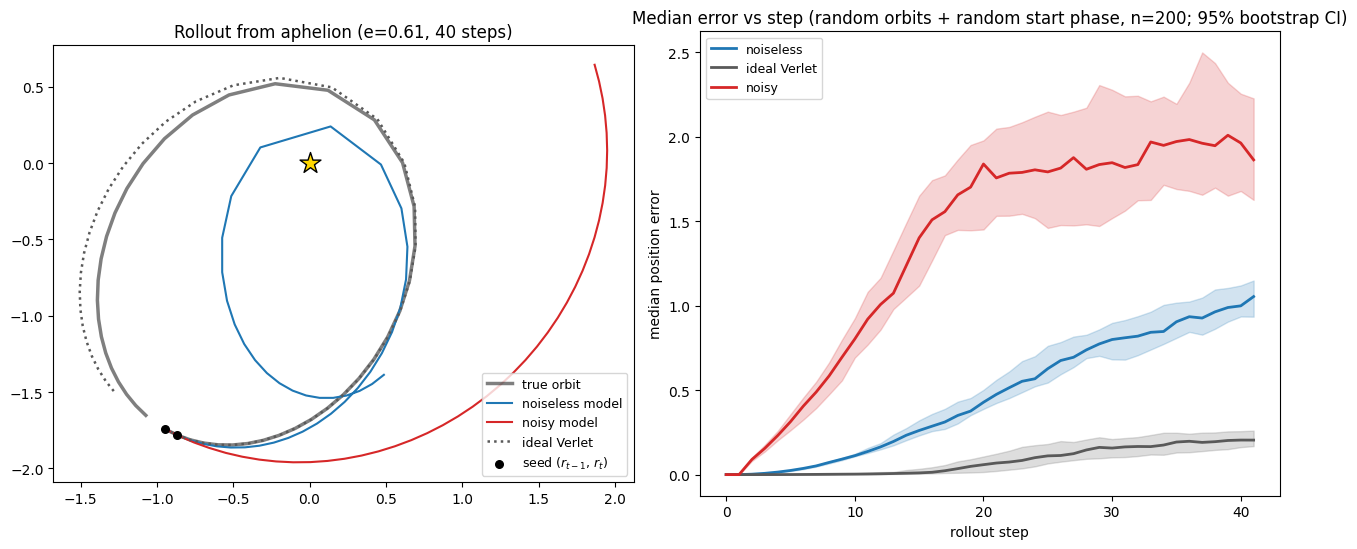

In [18]:
#| label: fig-rollout
#| fig-cap: "Autoregressive rollout on eccentric orbits (0.5 < e < 0.7), each seeded from two consecutive positions at a *random phase* along the orbit and rolled out 40 steps. Left: a single example orbit, drawn at random independently of the error-curve sample and seeded at aphelion, where dr/dt = 0 so the rollout leaves the orbit smoothly and the visible discrepancy is the heuristic's angular error rather than its radial one - at aphelion the local-circular rule turns too fast by 1/sqrt(1-e). It is illustrative only - which of the two models looks better by step 40 varies from draw to draw, so the quantitative comparison is the right-hand panel. Ideal Verlet (dotted) tracks the true ellipse; the noiseless model (blue) follows it closely for the first ~10 steps and then drifts off; the noisy model (red) leaves the ellipse immediately and circularises, drifting from its seed radius toward the radius it prefers. Right: median position error vs rollout step over a random, unbiased sample of 200 eccentric orbits (shaded 95% bootstrap CI of the median); ideal Verlet is integrated at the data's true sample spacing (dt = 20/99). Ideal Verlet is the most accurate throughout; the noiseless model accumulates error over the rollout but stays far closer to the true orbit than the noisy heuristic, whose error plateaus as it settles onto a wrong circular path (the residual wobble is the beat between the model's circular period and the true orbital period)."
#| code-fold: true
from analysis.elm import rollout, rollout_verlet
from analysis.data import load_orbital_params

N            = 40
N_ORBITS     = 200
EXAMPLE_SEED = 0     # re-roll the single example orbit in the left panel

with contextlib.redirect_stdout(io.StringIO()):
    _tr = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=OFFSET + 2000))
    _op = load_orbital_params(DATA_DIR, num_trajectories_needed=OFFSET + 2000)
_e = np.array([p['e'] for p in _op])

# all eccentric orbits in the loaded (test-split) pool, then an UNBIASED random sample
ecc_all = [i for i in range(OFFSET, OFFSET + 2000) if 0.5 < _e[i] < 0.7]
rng     = np.random.default_rng(SEED)
sample  = rng.choice(ecc_all, size=min(N_ORBITS, len(ecc_all)), replace=False)
# Seed each rollout from a RANDOM phase along its orbit. Every trajectory is
# generated starting at perihelion, so seeding from tr[:2] would phase-lock all
# orbits at minimum radius and manufacture a spurious oscillation in the median.
offsets = rng.integers(0, 100 - (N + 2) + 1, size=len(sample))

errs = {'noiseless': [], 'ideal Verlet': [], 'noisy': []}
for i, k in zip(sample, offsets):
    tr = _tr[i]; s = tr[k:k+2]; truth = tr[k:k+N+2]
    errs['noiseless'].append(np.linalg.norm(rollout(model_noiseless, s, N)   - truth, axis=1))
    errs['ideal Verlet'].append(np.linalg.norm(rollout_verlet(s, N, dt=DT) - truth, axis=1))
    errs['noisy'].append(np.linalg.norm(rollout(model_bs2, s, N)             - truth, axis=1))
errs = {k: np.array(v) for k, v in errs.items()}
step = np.arange(N + 2)

# bootstrap 95% CI of the median error at each step
def median_ci(m, n_boot=2000, seed=0):
    r = np.random.default_rng(seed)
    n = m.shape[0]
    med = np.median(m, axis=0)
    idx = r.integers(0, n, size=(n_boot, n))          # resample orbits with replacement
    boot = np.median(m[idx], axis=1)                  # (n_boot, n_steps)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    return med, lo, hi

# Example orbit: an independent random draw with its own RNG, so re-rolling the
# example (change EXAMPLE_SEED) leaves the error-curve sample untouched.
ex_rng = np.random.default_rng(EXAMPLE_SEED)
ei = int(ex_rng.choice(ecc_all))
true = _tr[ei]
# Start the example at APHELION -- the outermost point, found as the largest radius
# within the allowed start range. Like perihelion it has dr/dt = 0, so the rollout
# leaves the orbit smoothly and what stays visible is the heuristic's angular error
# rather than its radial one. Unlike perihelion it is also the *easiest* phase for a
# fixed-step integrator (slow motion, weak force): seeding at perihelion instead makes
# dt = 20/99 far too coarse for the 1/r^2 force there, and the ideal-Verlet reference
# itself takes a permanent energy hit, ending up less accurate than either model.
# The error curves on the right keep their random phases -- phase-locking those would
# manufacture a spurious oscillation in the median.
ek = int(np.argmax(np.linalg.norm(true[:100 - (N + 2) + 1], axis=1)))
s = true[ek:ek+2]; seg = true[ek:ek+N+2]
rn, rv, rx = rollout(model_noiseless, s, N), rollout_verlet(s, N, dt=DT), rollout(model_bs2, s, N)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.6))
axA.plot(seg[:, 0], seg[:, 1], 'k-', lw=2.5, alpha=0.5, label='true orbit')
axA.plot(rn[:, 0], rn[:, 1], '-',  color='tab:blue', lw=1.5, label='noiseless model')
axA.plot(rx[:, 0], rx[:, 1], '-',  color='tab:red',  lw=1.5, label='noisy model')
axA.plot(rv[:, 0], rv[:, 1], ':',  color='0.35',     lw=1.8, label='ideal Verlet')
axA.scatter(0, 0, marker='*', s=250, color='gold', edgecolor='k', zorder=5)
axA.scatter(s[:, 0], s[:, 1], color='k', s=30, zorder=5,
            label=r'seed ($r_{t-1}$, $r_t$)')
axA.set_aspect('equal'); axA.legend(fontsize=9)
axA.set_title(f'Rollout from aphelion (e={_e[ei]:.2f}, {N} steps)')

# right: MEDIAN error vs step over the random sample, with a 95% bootstrap CI band
for name, c in [('noiseless', 'tab:blue'), ('ideal Verlet', '0.35'), ('noisy', 'tab:red')]:
    med, lo, hi = median_ci(errs[name], seed=SEED)
    axB.plot(step, med, color=c, lw=2, label=name)
    axB.fill_between(step, lo, hi, color=c, alpha=0.2)
axB.set_xlabel('rollout step'); axB.set_ylabel('median position error')
axB.set_title(f'Median error vs step (random orbits + random start phase, n={len(sample)}; 95% bootstrap CI)')
axB.legend(fontsize=9)
fig.tight_layout(); plt.show()


@fig-rollout is the practical consequence of the mechanism. Seeded from two positions at a random phase of a held-out eccentric orbit, the noiseless model tracks the true ellipse well early in the rollout and then accumulates error as it proceeds: it has learned the *correct* one-step force (@fig-newton-behavioral), but it is a learned, approximate integrator, so small per-step errors compound and it never matches the accuracy of an ideal Verlet scheme, which stays closest to the truth throughout. The decisive comparison, though, is between the two *models*: the noiseless model stays far closer to the true orbit than the noisy one, which cannot track it at all. The noisy model's local circular-orbit heuristic quite literally **turns the ellipse into a circle**, missing the true orbit from the very first steps; its error is large but *bounded*, saturating as it settles onto a stable, wrong, circular path rather than diverging.

This is the point of reading out *how* a model computes, not just *what* it encodes. Both models "predict planetary motion"; both, by a linear probe, look like they know about force and geometry. But only one has learned a mechanism — Newtonian gravity — that generalises across orbit shapes; the other has learned a shortcut that works precisely where it was, in effect, assumed. Which one a transformer becomes is set not by its architecture but by the inductive bias of its training distribution.


## Discussion

Our analyses demonstrate that the noisy short-context model uses a circular orbit heuristic to predict planetary position rather than a proper Newtonian integrator. By removing input noise during training we show that the models do learn an approximation of genuine Verlet integration, encoding the gravitational kick as a negation in the effect applied to either input token. How do we square our analyses with the linear probe results reported by Liu et al.? 

The simplest explanation is that the apparent high decodability of Newtonian force components is simply a false positive result. The approach used to quantify these statistics probed all parts of the model, greedily selecting the most predictive components. Simultanesouly, there is no formal hypothesis test in this setting, and no null distribution of $R^2$ values to compare to. How unlikely is it to observe these extreme values by chance alone? This criticism was articulated by [Meloux et al. 2025], who call for more stringest statistical-causal reframing for these kinda of interpretability analyses. 

What if the $R^2$ values we observed are robust though? This leaves us in the somewhat vague world of definitions of world models. The noisy model uses a noise-robust circular heuristic that is *close* to what a proper Newtonian model would predict, at least for predicting one token into the future. It may well be that some transformation of this models representations could recover Newtonian force components, e.g. the heuristic speeds up the rotation depending on the planets radius from the sun, one could argue that this implicity captures some effect of gravity. So is this a Newtonian world model? 

Our approach to identifying learned world models is to focus on the computation of the model. The advantage here is we have an unambiguous definition of what it means for the transformers to have learned 'a Newtonian world model'. This is bolstered by fact that the Verlet integrator solution is direclty derived from Newtons laws. However, this is not a common definition fo world models in this space. The results from our rollout analysis also reveal one final tension that plagues our definition. It is virtually impossible for a stochastically fit model to learn the exact analytical solution to a Newtonian integrator. It comes close, but the tiny residual means that on rollout the model does deviate from the true integrator (the exact problem Liu et al were tackling with noisy training). In this case, how far do we accept our models solution to drift from the analytical Verlet expectation before we stop calling it Newtonian? The reality is that the labels for world model types are probably best viewed as somewhat continuous rather than abrupt switched. 